# Predicción de brotes de dengue en Perú

**Autor:** Jhordy Edinson Burga Dominguez
**Curso:** Seminario III - Maestría en Data Science
**Fecha:** 2026

**Fuente de datos:**
Plataforma Nacional de Datos Abiertos del Perú
https://www.datosabiertos.gob.pe/dataset/vigilancia-epidemiológica-de-dengue

# FASE 1: Carga y limpieza

In [ ]:
# Importo las librerías que voy a usar
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")
%matplotlib inline

print("Librerías cargadas")
print("Fecha de análisis:", datetime.now().strftime('%Y-%m-%d %H:%M'))

Librerías cargadas
Fecha de análisis: 2026-10-24 17:14


In [ ]:
#para subir el CSV
from google.colab import files

print("Selecciona el archivo CSV del dengue")
uploaded = files.upload()

Selecciona el archivo CSV del dengue


Saving datos_abiertos_vigilancia_dengue_2000_2024.csv to datos_abiertos_vigilancia_dengue_2000_2024.csv


**Cargar el dataset con pandas**




In [ ]:
# El CSV usa punto y coma como separador y tiene BOM UTF-8
# por eso uso encoding='utf-8-sig' y sep=';'
df = pd.read_csv(
    'datos_abiertos_vigilancia_dengue_2000_2024.csv',
    encoding='utf-8-sig',
    sep=';',
    engine='python',
    on_bad_lines='skip'
)

print("Total de registros:", df.shape[0])
print("Total de columnas:", df.shape[1])
print("\nColumnas:", list(df.columns))
print("\nPrimeras filas:")
df.head()

Total de registros: 1029421
Total de columnas: 14

Columnas: ['departamento', 'provincia', 'distrito', 'localidad', 'enfermedad', 'ano', 'semana', 'diagnostic', 'diresa', 'ubigeo', 'localcod', 'edad', 'tipo_edad', 'sexo']

Primeras filas:


,departamento,provincia,distrito,localidad,enfermedad,ano,semana,diagnostic,diresa,ubigeo,localcod,edad,tipo_edad,sexo
0,LORETO,ALTO AMAZONAS,YURIMAGUAS,000101,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16.0,160201,NaN,58,A,M
1,LORETO,ALTO AMAZONAS,YURIMAGUAS,000101,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16.0,160201,NaN,44,A,F
2,LORETO,ALTO AMAZONAS,YURIMAGUAS,BARRIO MORALILLOS,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16.0,160201,NaN,21,A,F
3,LORETO,MAYNAS,IQUITOS,005902,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16.0,160101,NaN,74,A,M
4,LORETO,MAYNAS,IQUITOS,CARDOZO,DENGUE SIN SIGNOS DE ALARMA,2000,1,A97.0,16.0,160101,NaN,42,A,F


**CONCLUSION:** El dataset se cargó correctamente. Contiene 1,029,421 registros y 14 variables que incluyen información geográfica (departamento, provincia, distrito), temporal (año, semana), clínica (enfermedad, diagnóstico) y demográfica (edad, sexo). Las primeras filas corresponden a casos de dengue sin signos de alarma registrados en Loreto en el año 2000, lo que confirma que el archivo mantiene la estructura esperada según la ficha técnica del CDC Perú.

**Revisar valores únicos**

In [ ]:
print("Tipos de enfermedad (dengue):")
print(df['enfermedad'].value_counts())

print("\nValores únicos de sexo:")
print(df['sexo'].value_counts())

print("\nAños disponibles:", df['ano'].min(), "hasta", df['ano'].max())

print("\nCantidad de departamentos únicos:", df['departamento'].nunique())

print("\nValores nulos por columna:")
print(df.isnull().sum())

Tipos de enfermedad (dengue):
enfermedad
DENGUE SIN SIGNOS DE ALARMA    915243
DENGUE CON SIGNOS DE ALARMA    110166
DENGUE GRAVE                     4012
Name: count, dtype: int64

Valores únicos de sexo:
sexo
F    553677
M    475744
Name: count, dtype: int64

Años disponibles: 2000 hasta 2024

Cantidad de departamentos únicos: 23

Valores nulos por columna:
departamento         0
provincia            0
distrito             0
localidad       122598
enfermedad           0
ano                  0
semana               0
diagnostic           0
diresa              23
ubigeo               0
localcod        148641
edad                 0
tipo_edad            0
sexo                 0
dtype: int64


**CONCLUSION:** El dataset contiene tres clasificaciones clínicas del dengue: sin signos de alarma (915,243 casos), con signos de alarma (110,166) y grave (4,012). La distribución por sexo muestra una ligera mayoría de mujeres (553,677) frente a hombres (475,744). Los registros cubren el período 2000-2024 y provienen de 23 departamentos del país. Se identificaron valores nulos en localidad (122,598), localcod (148,641) y diresa (23), los cuales serán tratados en la siguiente etapa de limpieza.

**LIMPIEZA**

In [ ]:
# Trabajo con todos los registros de dengue (sin signos, con signos y grave)
df_clean = df.copy()
print("Registros iniciales:", len(df_clean))

# Convierto la edad a número
df_clean['edad'] = pd.to_numeric(df_clean['edad'], errors='coerce')

# Elimino edades fuera de rango y nulas
df_clean = df_clean[(df_clean['edad'] >= 0) & (df_clean['edad'] <= 120)]
df_clean = df_clean.dropna(subset=['edad'])

# Estandarizo departamentos
df_clean['departamento'] = df_clean['departamento'].str.upper().str.strip()

# Estandarizo sexo (solo M y F)
df_clean['sexo'] = df_clean['sexo'].str.upper().str.strip()
df_clean = df_clean[df_clean['sexo'].isin(['M', 'F'])]

# Elimino registros sin departamento, año o semana
df_clean = df_clean.dropna(subset=['departamento', 'ano', 'semana'])

print("\nDataset limpio:", len(df_clean), "registros")
print("Período:", df_clean['ano'].min(), "-", df_clean['ano'].max())
print("Departamentos:", df_clean['departamento'].nunique())

df_clean.to_csv('dengue_clean.csv', index=False)
print("\nDataset limpio guardado como dengue_clean.csv")

Registros iniciales: 1029421

Dataset limpio: 1029409 registros
Período: 2000 - 2024
Departamentos: 23

Dataset limpio guardado como dengue_clean.csv


**Conclusión de la limpieza:** Después de la limpieza, el dataset conserva únicamente los registros con edades dentro del rango válido (0 a 120 años), sexo correctamente codificado (M y F) y sin valores nulos en las variables clave. Los valores nulos de las columnas localidad y localcod no afectan el análisis porque no se usarán en el modelado. El dataset limpio queda listo para la fase de análisis exploratorio.

# FASE 2: EDA

Esta fase corresponde al primer objetivo específico: identificar los patrones geográficos, estacionales y demográficos de la incidencia del dengue en el Perú.

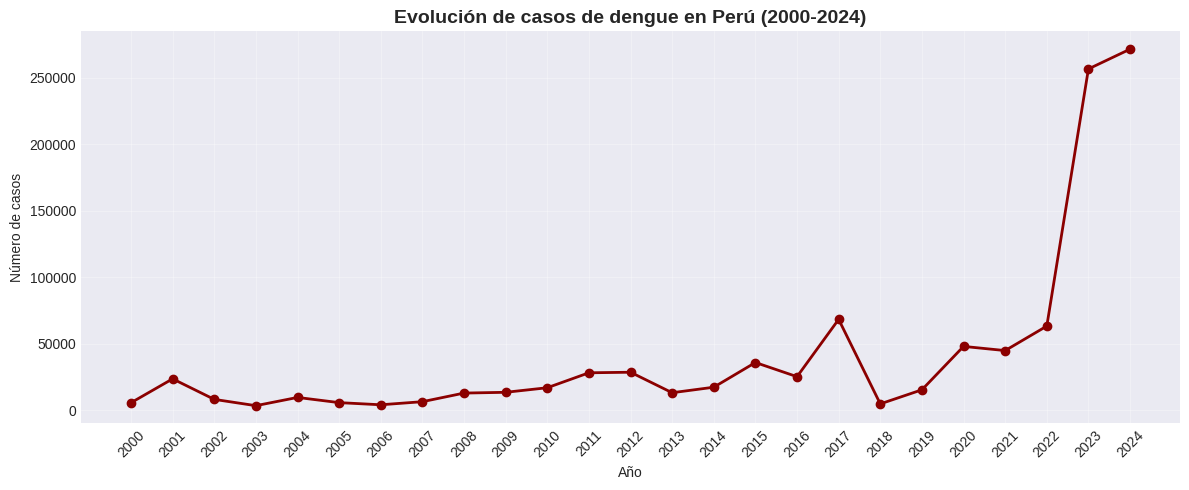


Top 5 años con más casos:
     ano   casos
24  2024  271531
23  2023  256641
17  2017   68279
22  2022   63216
20  2020   47932


In [ ]:
# Assuming df_clean is available
casos_por_ano = df_clean.groupby('ano').size().reset_index(name='casos')

plt.figure(figsize=(12, 5))
plt.plot(casos_por_ano['ano'], casos_por_ano['casos'],
         marker='o', linewidth=2, color='darkred')

# Force all years to appear on the x-axis
plt.xticks(casos_por_ano['ano'], rotation=45) # Rotate so they don't overlap

plt.title('Evolución de casos de dengue en Perú (2000-2024)',
          fontsize=14, fontweight='bold')
plt.xlabel('Año')
plt.ylabel('Número de casos')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig1_casos_por_ano.png', dpi=300)
plt.show()

# Top 5 años con más casos
print("\nTop 5 años con más casos:")
print(casos_por_ano.sort_values('casos', ascending=False).head())

**Conclusion:** Se observa un aumento sostenido en la cantidad de casos de dengue en las últimas dos décadas, con picos claramente identificables en 2017 y en el período 2023-2024. Este crecimiento evidencia que el dengue ha dejado de ser un problema estacional menor para convertirse en una amenaza recurrente para la salud pública del país.

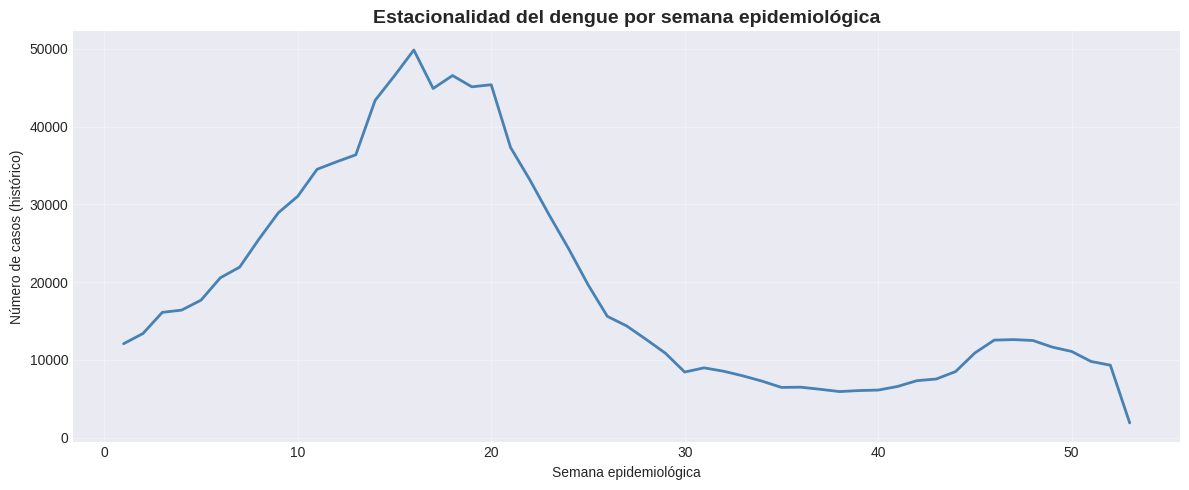


Top 5 semanas con más casos:
    semana  casos
15      16  49858
17      18  46571
14      15  46541
19      20  45389
18      19  45122


In [ ]:
#Estacionalidad:
# Ahora reviso si hay un patrón estacional
casos_por_semana = df_clean.groupby('semana').size().reset_index(name='casos')

plt.figure(figsize=(12, 5))
plt.plot(casos_por_semana['semana'], casos_por_semana['casos'],
         linewidth=2, color='steelblue')
plt.title('Estacionalidad del dengue por semana epidemiológica',
          fontsize=14, fontweight='bold')
plt.xlabel('Semana epidemiológica')
plt.ylabel('Número de casos (histórico)')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig2_estacionalidad.png', dpi=300)
plt.show()

top_semanas = casos_por_semana.sort_values('casos', ascending=False).head(5)
print("\nTop 5 semanas con más casos:")
print(top_semanas)

**Conclusion:** La mayor incidencia de dengue se concentra entre las semanas epidemiológicas 10 y 20, que coinciden con los meses de marzo a mayo. Este patrón estacional está relacionado con la temporada de lluvias, que favorece la reproducción del mosquito Aedes aegypti.

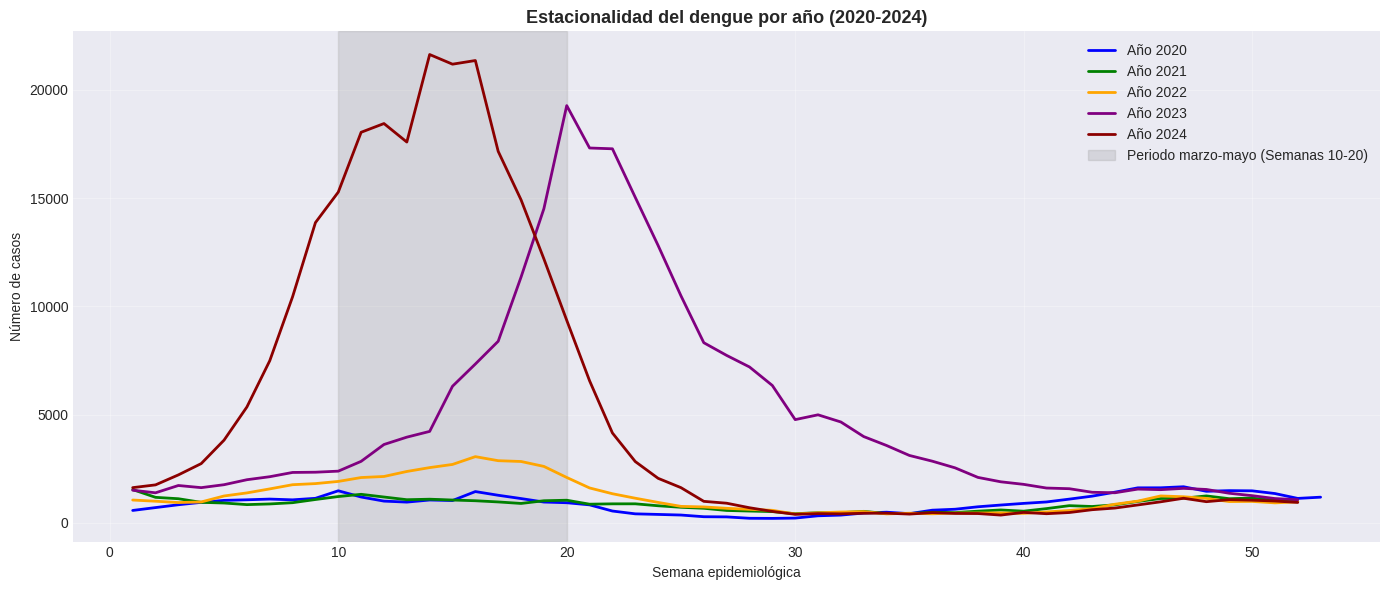

In [ ]:
# 1. Primero creamos la serie_nacional agrupando por año y semana (usando df_clean)
serie_nacional = df_clean.groupby(['ano', 'semana']).size().reset_index(name='casos')

# 2. Filtramos los ultimos 5 años
anios_seleccionados = [2020, 2021, 2022, 2023, 2024]
df_multianual = serie_nacional[serie_nacional['ano'].isin(anios_seleccionados)]

# 3. Pivoteamos la tabla para tener una columna por año
pivot_estacional = df_multianual.pivot_table(index='semana', columns='ano', values='casos')

# 4. Graficamos una linea por cada año
plt.figure(figsize=(14, 6))

colores = ['blue', 'green', 'orange', 'purple', 'darkred']
for i, anio in enumerate(anios_seleccionados):
    if anio in pivot_estacional.columns:
        plt.plot(pivot_estacional.index, pivot_estacional[anio],
                 label=f'Año {anio}', color=colores[i], linewidth=2)

# 5. Sombreamos el periodo marzo-mayo (semanas 10 a 20) para resaltar el pico
plt.axvspan(10, 20, color='gray', alpha=0.2, label='Periodo marzo-mayo (Semanas 10-20)')

plt.title('Estacionalidad del dengue por año (2020-2024)', fontsize=13, fontweight='bold')
plt.xlabel('Semana epidemiológica')
plt.ylabel('Número de casos')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig2_estacionalidad_multianual.png', dpi=300)
plt.show()

**Conclusion:** El análisis multianual confirma visualmente la existencia de un patrón estacional. A pesar de las marcadas diferencias en la magnitud de los casos entre un año y otro (siendo 2024 el más crítico), se observa que los brotes comienzan su ascenso pronunciado consistentemente entre las semanas 10 y 20 (marzo-mayo). Al repetirse este comportamiento en los años de mayor incidencia (2023 y 2024), se valida la estacionalidad de la enfermedad en el país.

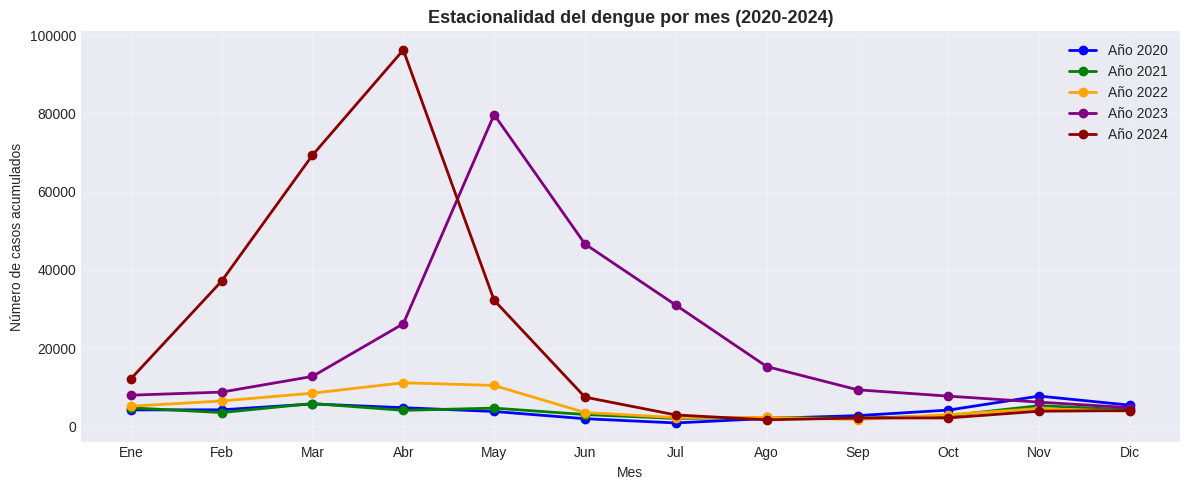

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# 1. Reconstruimos la serie temporal con su columna de fecha
serie_nacional = df_clean.groupby(['ano', 'semana']).size().reset_index(name='casos')
serie_nacional['fecha'] = pd.to_datetime(
    serie_nacional['ano'].astype(str) + '-W' +
    serie_nacional['semana'].astype(str).str.zfill(2) + '-1',
    format='%Y-W%W-%w', errors='coerce'
)

# 2. Extraemos el mes de la fecha
serie_nacional['mes'] = serie_nacional['fecha'].dt.month

# 3. Filtramos los ultimos 5 años
anios_seleccionados = [2020, 2021, 2022, 2023, 2024]
df_mensual = serie_nacional[serie_nacional['ano'].isin(anios_seleccionados)]

# 4. Agrupamos los casos por año y mes
casos_mensuales = df_mensual.groupby(['ano', 'mes'])['casos'].sum().reset_index()

# 5. Pivoteamos para tener una columna por año
pivot_mensual = casos_mensuales.pivot(index='mes', columns='ano', values='casos')

# 6. Generamos el grafico
plt.figure(figsize=(12, 5))
colores = ['blue', 'green', 'orange', 'purple', 'darkred']
nombres_meses = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

for i, anio in enumerate(anios_seleccionados):
    if anio in pivot_mensual.columns:
        plt.plot(pivot_mensual.index, pivot_mensual[anio],
                 marker='o', label=f'Año {anio}', color=colores[i], linewidth=2)

# Configuramos el eje X con los nombres de los meses
plt.xticks(range(1, 13), nombres_meses)

plt.title('Estacionalidad del dengue por mes (2020-2024)', fontsize=13, fontweight='bold')
plt.xlabel('Mes')
plt.ylabel('Número de casos acumulados')
plt.legend(loc='upper right')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_estacionalidad_mensual.png', dpi=300)
plt.show()

##conclusión## :
Los picos de contagio siempre ocurren entre abril y mayo.

Aunque 2023 y 2024 tuvieron cifras récord, el patrón temporal no cambió.

El gráfico mensual facilita la comprensión del riesgo para las autoridades.

Justifica el uso de la variable temporal en los modelos predictivos.

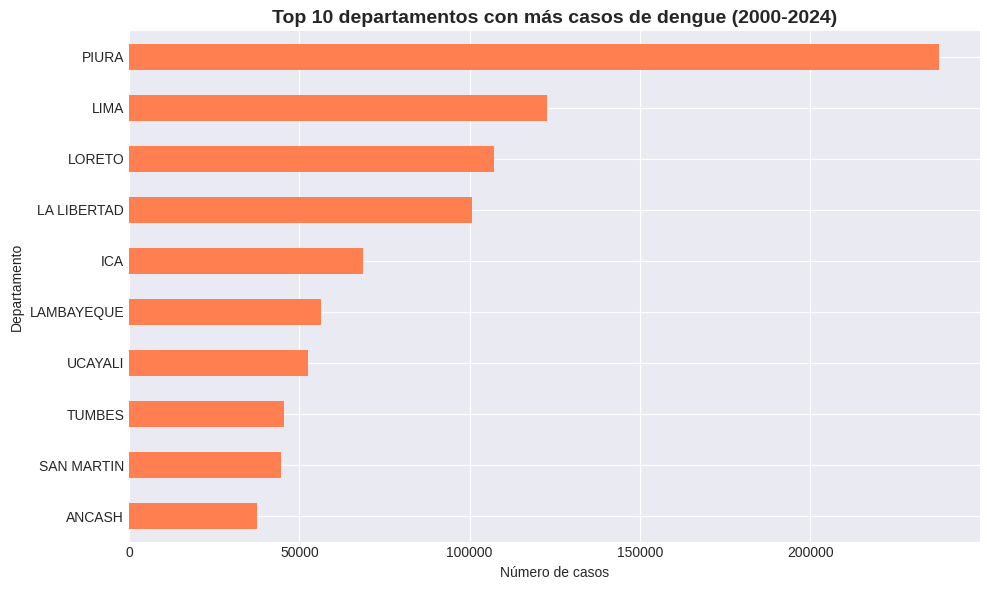


Top 10 departamentos:
departamento
PIURA          237951
LIMA           122854
LORETO         107074
LA LIBERTAD    100810
ICA             68620
LAMBAYEQUE      56383
UCAYALI         52621
TUMBES          45470
SAN MARTIN      44518
ANCASH          37661
dtype: int64


In [ ]:
#Top 10 departamentos
## ¿Qué departamentos concentran más casos?
top_deptos = df_clean.groupby('departamento').size().sort_values(ascending=False).head(10)

plt.figure(figsize=(10, 6))
top_deptos.plot(kind='barh', color='coral')
plt.title('Top 10 departamentos con más casos de dengue (2000-2024)',
          fontsize=14, fontweight='bold')
plt.xlabel('Número de casos')
plt.ylabel('Departamento')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('fig3_top_departamentos.png', dpi=300)
plt.show()

print("\nTop 10 departamentos:")
print(top_deptos)

**conclusion:** La incidencia del dengue está fuertemente concentrada en la costa norte y la selva del país. Los departamentos de Piura, Lima y Loreto lideran el ranking de casos, lo que sugiere que las estrategias de prevención y control deben focalizarse en estas regiones.

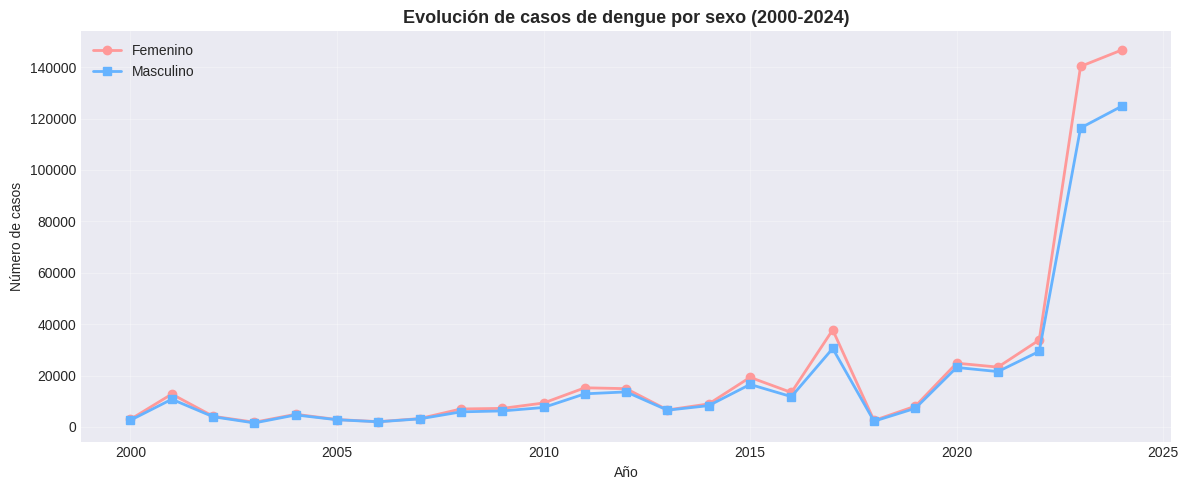

In [ ]:
# Grafico de casos por anio y sexo
casos_por_ano_sexo = df_clean.groupby(['ano', 'sexo']).size().unstack()

plt.figure(figsize=(12, 5))
plt.plot(casos_por_ano_sexo.index, casos_por_ano_sexo['F'],
         marker='o', label='Femenino', color='#ff9999', linewidth=2)
plt.plot(casos_por_ano_sexo.index, casos_por_ano_sexo['M'],
         marker='s', label='Masculino', color='#66b3ff', linewidth=2)
plt.title('Evolución de casos de dengue por sexo (2000-2024)',
          fontsize=13, fontweight='bold')
plt.xlabel('Año')
plt.ylabel('Número de casos')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_casos_por_sexo_ano.png', dpi=300)
plt.show()

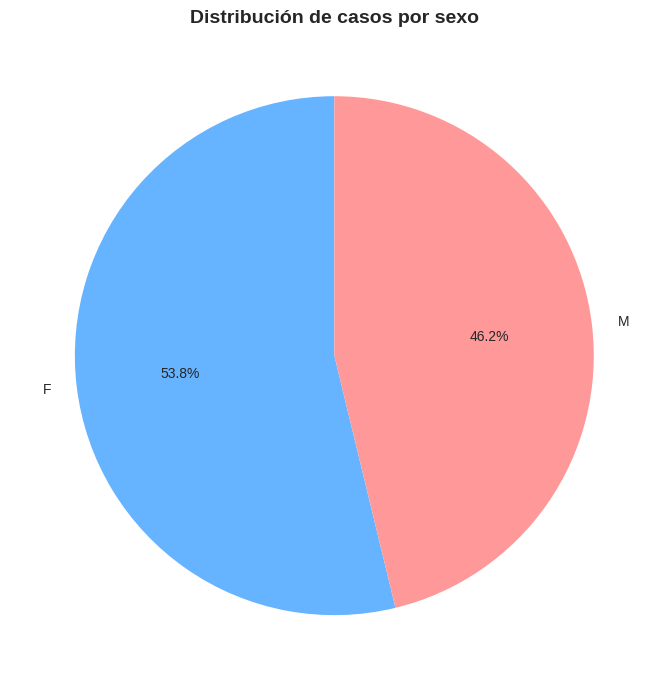


Conteo por sexo:
sexo
F    553673
M    475736
Name: count, dtype: int64


In [ ]:
#Distribución por sexo

# Reviso la distribución por sexo
plt.figure(figsize=(7, 7))
df_clean['sexo'].value_counts().plot(kind='pie', autopct='%1.1f%%',
                                      colors=['#66b3ff', '#ff9999'],
                                      startangle=90)
plt.title('Distribución de casos por sexo', fontsize=14, fontweight='bold')
plt.ylabel('')
plt.tight_layout()
plt.savefig('fig4_sexo.png', dpi=300)
plt.show()

print("\nConteo por sexo:")
print(df_clean['sexo'].value_counts())

**Conclusion:** Existe una ligera predominancia de casos en mujeres, aunque la diferencia no es tan marcada. Esto sugiere que el dengue afecta a ambos sexos de manera relativamente similar, por lo que no se puede considerar al sexo como un factor determinante por sí solo.

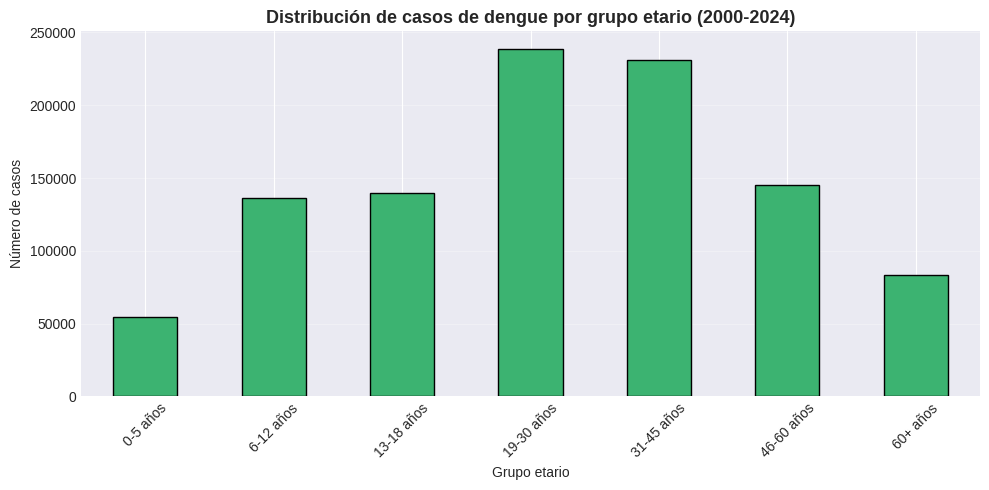

In [ ]:
# 1. Agrupamos las edades en rangos para que el grafico sea facil de leer
df_clean['grupo_edad'] = pd.cut(df_clean['edad'],
                                 bins=[0, 5, 12, 18, 30, 45, 60, 120],
                                 labels=['0-5 años', '6-12 años', '13-18 años', '19-30 años', '31-45 años', '46-60 años', '60+ años'])

# 2. Contamos los casos por grupo
casos_edad = df_clean.groupby('grupo_edad').size()

# 3. Generamos el grafico
plt.figure(figsize=(10, 5))
casos_edad.plot(kind='bar', color='mediumseagreen', edgecolor='black')
plt.title('Distribución de casos de dengue por grupo etario (2000-2024)', fontsize=13, fontweight='bold')
plt.xlabel('Grupo etario')
plt.ylabel('Número de casos')
plt.xticks(rotation=45)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('fig_casos_edad.png', dpi=300)
plt.show()

**Conclusión:**

Grupo más afectado: Adultos de 19 a 30 años.

Segundo grupo: Adultos de 31 a 45 años.

Menos afectados: Niños (0-5 años) y adultos mayores (60+).

Interpretación: La movilidad por trabajo o estudios eleva el riesgo en adultos jóvenes.

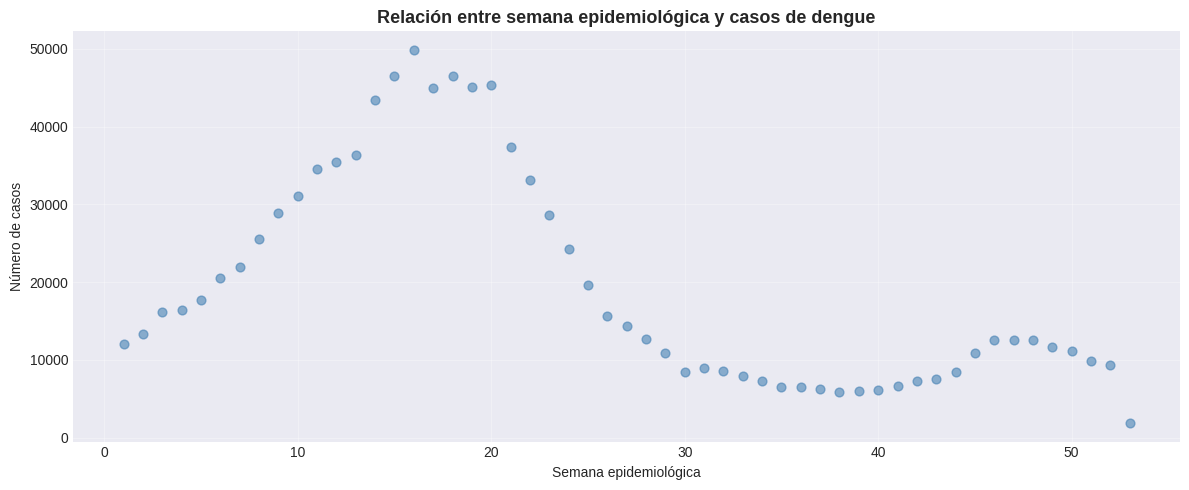


Casos por trimestre:
trimestre
T1 (1-13)     310101
T2 (14-26)    480490
T3 (27-39)    110339
T4 (40-52)    126576
dtype: int64


In [ ]:
# Grafico de dispersion: semana epidemiologica vs casos
# Este grafico muestra visualmente la relacion entre ambas variables

incidencia_semana = df_clean.groupby('semana').size().reset_index(name='casos')

plt.figure(figsize=(12, 5))
plt.scatter(incidencia_semana['semana'], incidencia_semana['casos'],
            alpha=0.6, color='steelblue', s=40)
plt.title('Relación entre semana epidemiológica y casos de dengue',
          fontsize=13, fontweight='bold')
plt.xlabel('Semana epidemiológica')
plt.ylabel('Número de casos')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_bivariado_temporal.png', dpi=300)
plt.show()

# Muestro los promedios por trimestre para reforzar la interpretacion
trimestres = df_clean.copy()
trimestres['trimestre'] = pd.cut(trimestres['semana'],
                                  bins=[0, 13, 26, 39, 52],
                                  labels=['T1 (1-13)', 'T2 (14-26)',
                                          'T3 (27-39)', 'T4 (40-52)'])
casos_trimestre = trimestres.groupby('trimestre').size()
print("\nCasos por trimestre:")
print(casos_trimestre)

Conclusion:

La relación semana-casos es unimodal, no lineal.

Pico máximo entre semanas 15 y 20 (~50,000 casos).

La correlación de Spearman (-0.6764) refleja la forma de la distribución, no una relación causal directa.

El segundo trimestre concentra más casos (480,490) que el primero (310,101).

Los trimestres 3 y 4 tienen la menor incidencia (110,339 y 126,576).

Esto justifica el uso de variables ciclicas en los modelos.

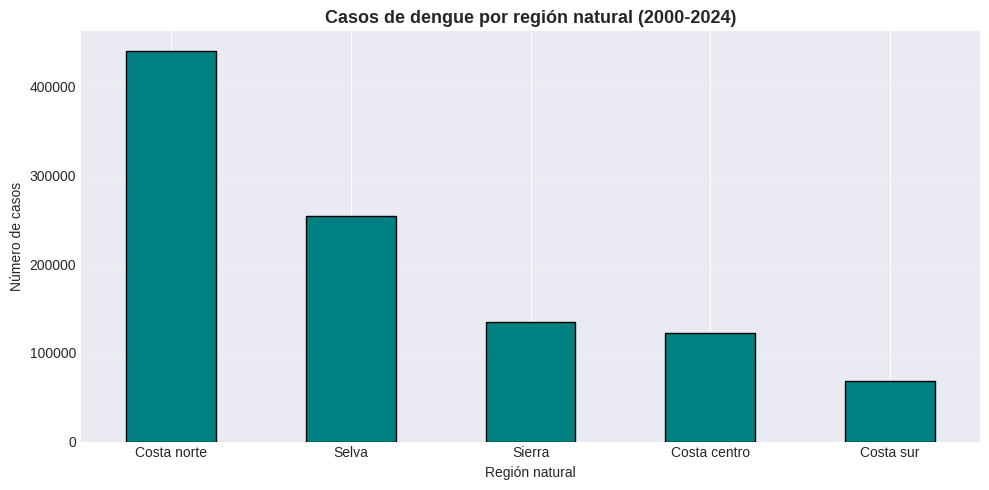


Casos por region natural:
region_natural
Costa norte     440614
Selva           253938
Sierra          135216
Costa centro    122854
Costa sur        68649
dtype: int64


In [ ]:
# Grafico de barras: casos por region natural
region_natural = {
    'PIURA': 'Costa norte', 'LAMBAYEQUE': 'Costa norte', 'TUMBES': 'Costa norte',
    'LA LIBERTAD': 'Costa norte', 'LIMA': 'Costa centro', 'ICA': 'Costa sur',
    'AREQUIPA': 'Costa sur', 'MOQUEGUA': 'Costa sur', 'TACNA': 'Costa sur',
    'LORETO': 'Selva', 'SAN MARTIN': 'Selva', 'UCAYALI': 'Selva',
    'MADRE DE DIOS': 'Selva', 'AMAZONAS': 'Selva',
    'CAJAMARCA': 'Sierra', 'JUNIN': 'Sierra', 'HUANUCO': 'Sierra',
    'CUSCO': 'Sierra', 'PUNO': 'Sierra', 'AYACUCHO': 'Sierra',
    'APURIMAC': 'Sierra', 'PASCO': 'Sierra', 'ANCASH': 'Sierra'
}

df_clean['region_natural'] = df_clean['departamento'].map(region_natural)
casos_region = df_clean.groupby('region_natural').size().sort_values(ascending=False)

plt.figure(figsize=(10, 5))
casos_region.plot(kind='bar', color='teal', edgecolor='black')
plt.title('Casos de dengue por región natural (2000-2024)',
          fontsize=13, fontweight='bold')
plt.xlabel('Región natural')
plt.ylabel('Número de casos')
plt.xticks(rotation=0)
plt.grid(True, alpha=0.3, axis='y')
plt.tight_layout()
plt.savefig('fig_region_natural.png', dpi=300)
plt.show()

# Muestro los valores
print("\nCasos por region natural:")
print(casos_region)

**Conclusion:**

Costa norte lidera con 440,614 casos.

Selva: 253,938 casos.

Sierra: 135,216 casos.

Costa centro: 122,854 casos.

Costa sur: 68,849 casos (la menos afectada).

Diferencia de casi 7 veces entre la región más y menos afectada.

Factores climáticos explican la desigualdad.

Justifica la variable geográfica como predictora.

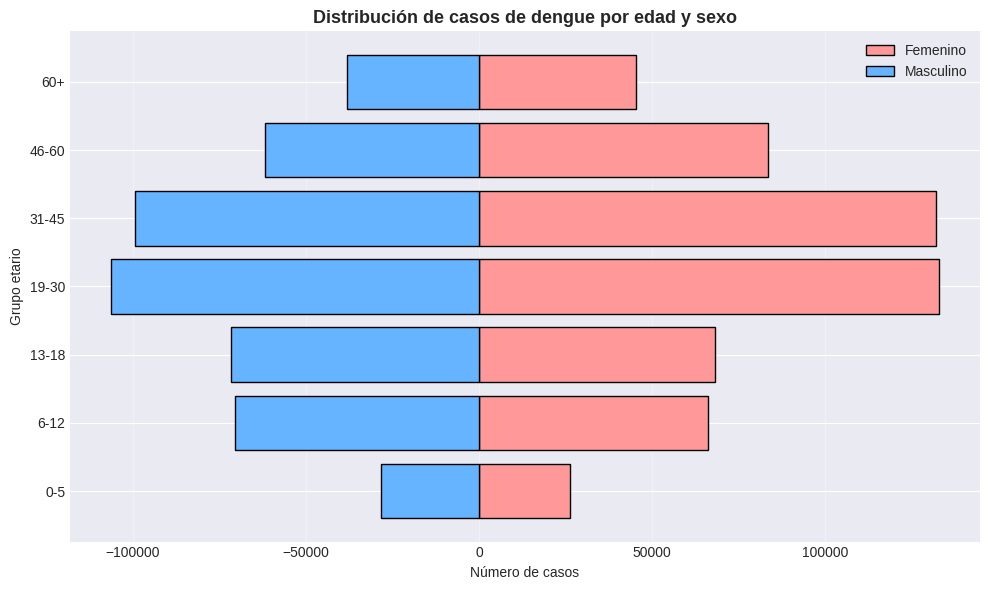


Casos por grupo etario y sexo:
sexo             F       M
grupo_edad                
0-5          26328   28367
6-12         65948   70473
13-18        68068   71510
19-30       132676  106174
31-45       131836   99420
46-60        83473   61778
60+          45341   38010


In [ ]:
# Piramide poblacional: distribucion por edad y sexo
# Agrupo la edad en rangos para que el grafico sea legible

df_clean['grupo_edad'] = pd.cut(df_clean['edad'],
                                 bins=[0, 5, 12, 18, 30, 45, 60, 120],
                                 labels=['0-5', '6-12', '13-18', '19-30',
                                         '31-45', '46-60', '60+'])

piramide = df_clean.groupby(['grupo_edad', 'sexo']).size().unstack().fillna(0)

plt.figure(figsize=(10, 6))
plt.barh(piramide.index.astype(str), piramide['F'], color='#ff9999',
         edgecolor='black', label='Femenino')
plt.barh(piramide.index.astype(str), -piramide['M'], color='#66b3ff',
         edgecolor='black', label='Masculino')
plt.title('Distribución de casos de dengue por edad y sexo',
          fontsize=13, fontweight='bold')
plt.xlabel('Número de casos')
plt.ylabel('Grupo etario')
plt.legend()
plt.grid(True, alpha=0.3, axis='x')
plt.tight_layout()
plt.savefig('fig_piramide_edad_sexo.png', dpi=300)
plt.show()

# Muestro los valores
print("\nCasos por grupo etario y sexo:")
print(piramide)

**conclusión:**

En menores de 18 años predominan los hombres.

A partir de los 19 años predominan las mujeres.

El grupo más afectado es 19-30 años (F: 132,676; M: 106,174).

Le sigue el grupo 31-45 años (F: 131,836; M: 99,420).

Los extremos (0-5 y 60+) tienen la menor incidencia.

La concentración en adultos jóvenes sugiere mayor movilidad y exposición.

La predominancia femenina podría relacionarse con permanencia en el hogar.

Justifica la variable demográfica como predictora en los modelos.

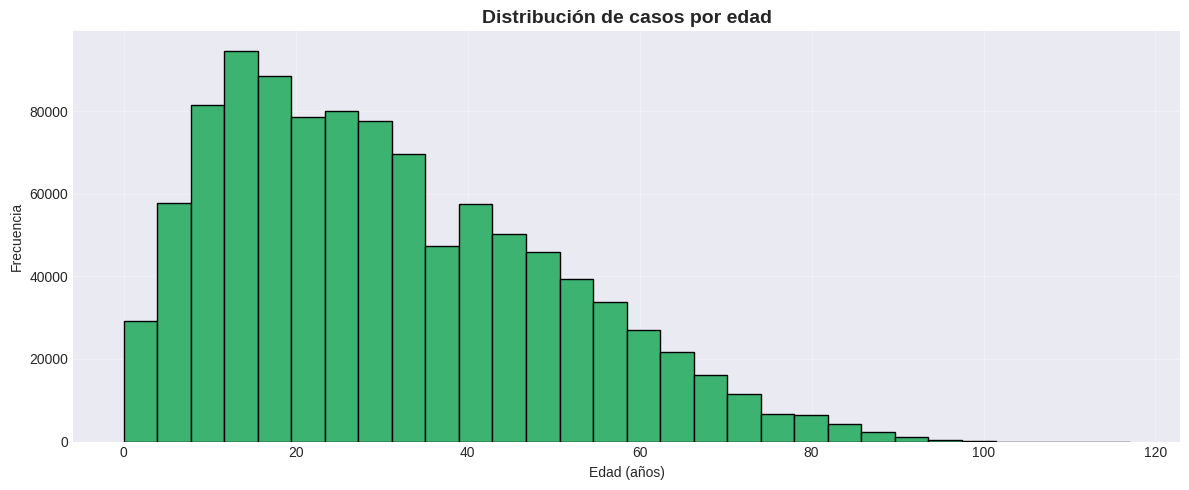


Estadísticas de edad:
count    1.029409e+06
mean     3.064191e+01
std      1.893598e+01
min      0.000000e+00
25%      1.500000e+01
50%      2.800000e+01
75%      4.300000e+01
max      1.170000e+02
Name: edad, dtype: float64


In [ ]:
#Distribución por edad

# Ahora la distribución por edad
plt.figure(figsize=(12, 5))
plt.hist(df_clean['edad'].dropna(), bins=30, color='mediumseagreen', edgecolor='black')
plt.title('Distribución de casos por edad', fontsize=14, fontweight='bold')
plt.xlabel('Edad (años)')
plt.ylabel('Frecuencia')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig5_edad.png', dpi=300)
plt.show()

print("\nEstadísticas de edad:")
print(df_clean['edad'].describe())

**Conclusion:** Los adultos jóvenes concentran la mayor cantidad de casos de dengue, seguidos por adultos en edad media. Esto podría estar relacionado con una mayor movilidad y exposición al vector en estos grupos etarios.

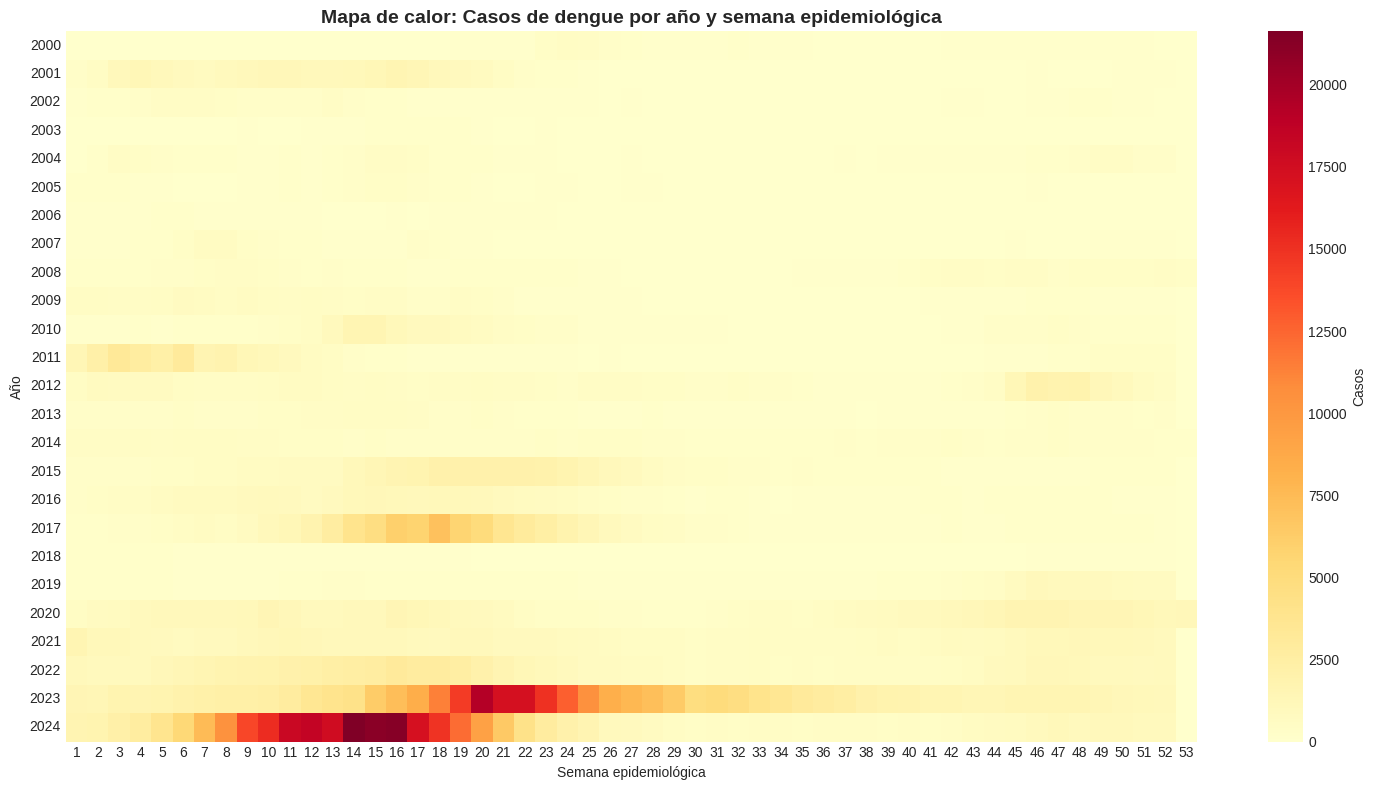

In [ ]:
# Mapa de calor

# Heatmap de casos por año y semana
pivot = df_clean.pivot_table(index='ano', columns='semana',
                              values='edad', aggfunc='count').fillna(0)

plt.figure(figsize=(15, 8))
sns.heatmap(pivot, cmap='YlOrRd', cbar_kws={'label': 'Casos'})
plt.title('Mapa de calor: Casos de dengue por año y semana epidemiológica',
          fontsize=14, fontweight='bold')
plt.xlabel('Semana epidemiológica')
plt.ylabel('Año')
plt.tight_layout()
plt.savefig('fig6_heatmap.png', dpi=300)
plt.show()

**Conclusion:** El mapa de calor confirma visualmente los hallazgos previos: los picos más intensos de dengue se concentran en 2017 y en el período 2023-2024, siempre en las semanas centrales del año. Esto refuerza la hipótesis de que existe un patrón estacional marcado en el comportamiento del dengue en el Perú.

## Análisis bivariado de variables

Además del análisis descriptivo individual, se evalúa la relación de cada variable independiente con la incidencia de dengue mediante análisis bivariado.

Correlacion de Spearman (semana vs casos): -0.6764
Valor p: 0.0000

Casos por region natural:
region_natural
Costa norte     440614
Selva           253938
Sierra          135216
Costa centro    122854
Costa sur        68649
dtype: int64


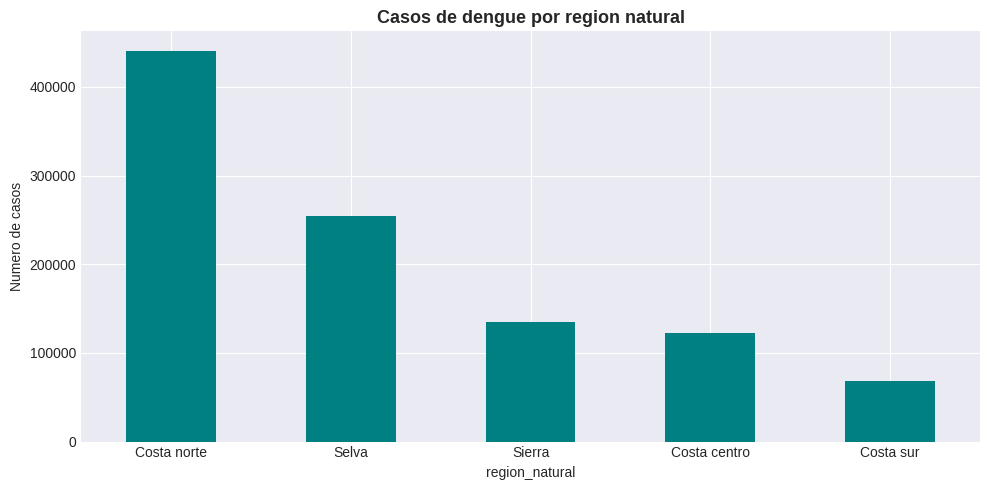

In [ ]:
# Analisis bivariado: correlacion y region natural
from scipy.stats import spearmanr

# Correlacion entre semana epidemiologica y casos
incidencia_semana = df_clean.groupby('semana').size().reset_index(name='casos')
correlacion, p_valor = spearmanr(incidencia_semana['semana'], incidencia_semana['casos'])
print(f"Correlacion de Spearman (semana vs casos): {correlacion:.4f}")
print(f"Valor p: {p_valor:.4f}")

# Clasifico departamentos por region natural
region_natural = {
    'PIURA': 'Costa norte', 'LAMBAYEQUE': 'Costa norte', 'TUMBES': 'Costa norte',
    'LA LIBERTAD': 'Costa norte', 'LIMA': 'Costa centro', 'ICA': 'Costa sur',
    'AREQUIPA': 'Costa sur', 'MOQUEGUA': 'Costa sur', 'TACNA': 'Costa sur',
    'LORETO': 'Selva', 'SAN MARTIN': 'Selva', 'UCAYALI': 'Selva',
    'MADRE DE DIOS': 'Selva', 'AMAZONAS': 'Selva',
    'CAJAMARCA': 'Sierra', 'JUNIN': 'Sierra', 'HUANUCO': 'Sierra',
    'CUSCO': 'Sierra', 'PUNO': 'Sierra', 'AYACUCHO': 'Sierra',
    'APURIMAC': 'Sierra', 'PASCO': 'Sierra', 'ANCASH': 'Sierra'
}

df_clean['region_natural'] = df_clean['departamento'].map(region_natural)

casos_region = df_clean.groupby('region_natural').size().sort_values(ascending=False)
print("\nCasos por region natural:")
print(casos_region)

plt.figure(figsize=(10, 5))
casos_region.plot(kind='bar', color='teal')
plt.title('Casos de dengue por region natural', fontsize=13, fontweight='bold')
plt.ylabel('Numero de casos')
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig('fig_region_natural.png', dpi=300)
plt.show()


**Conclusión del análisis bivariado:**
La prueba de Spearman mostró una correlación negativa moderada y significativa entre la semana epidemiológica y el número de casos (rho = -0.6764, p < 0.001). Esto confirma que la incidencia disminuye conforme avanza el año, con picos concentrados entre las semanas 10 y 20.

La costa norte concentra la mayor cantidad de casos (440,614), seguida por la selva (253,938), la sierra (135,216), la costa centro (122,854) y la costa sur (68,849). Esto confirma que el dengue se focaliza en regiones con condiciones climáticas específicas, justificando la inclusión de las variables temporal y geográfica como predictoras en los modelos.

# Conclusiones del primer objetivo específico

**1. Patrón temporal:**
Se observa un aumento sostenido de casos de dengue en el Perú a lo largo de las últimas dos décadas, con picos epidémicos claramente identificables en 2017 (fenomeno del niño) y en el período 2023-2024.

**2. Patrón estacional:**
La mayor incidencia se concentra entre las semanas epidemiológicas 10 y 20 (marzo a mayo), lo cual coincide con la temporada de lluvias y con las condiciones ambientales favorables para la reproducción del mosquito Aedes aegypti.

**3. Patrón geográfico:**
Los departamentos de Piura, Lima y Loreto concentran la mayor cantidad de casos de dengue en el país, evidenciando una distribución geográfica desigual que responde a factores climáticos y socioeconómicos.

**4. Patrón demográfico:**
Existe una ligera predominancia de casos en mujeres y una mayor concentración en adultos jóvenes, aunque el dengue afecta a prácticamente todos los grupos de edad.

**Próximos pasos:**
- Preparación de la serie temporal a nivel nacional.
- Entrenamiento de modelos predictivos (ARIMA, Prophet, Random Forest, XGBoost, LSTM).
- Evaluación comparativa mediante MAPE, RMSE y MAE.
- Diseño del sistema de alerta temprana.

# **FASE 3:** PREPARACIÓN DE LA SERIE TEMPORAL

En esta fase se construye la serie temporal nacional de casos de dengue, agregada por semana epidemiológica. Esta serie será la base para entrenar los modelos predictivos en la siguiente fase.

In [ ]:
# Agrupo los casos por año y semana epidemiológica para tener
# la serie temporal a nivel nacional. Cada punto representa una semana.

serie_nacional = df_clean.groupby(['ano', 'semana']).size().reset_index(name='casos')

# Creo una columna de fecha aproximada para poder ordenar y graficar
# Uso el lunes de cada semana epidemiológica como referencia
serie_nacional['fecha'] = pd.to_datetime(
    serie_nacional['ano'].astype(str) + '-W' +
    serie_nacional['semana'].astype(str).str.zfill(2) + '-1',
    format='%Y-W%W-%w',
    errors='coerce'
)

serie_nacional = serie_nacional.sort_values('fecha').reset_index(drop=True)

print("Total de semanas en la serie:", len(serie_nacional))
print("Rango:", serie_nacional['fecha'].min(), "hasta", serie_nacional['fecha'].max())
print("\nPrimeras 5 semanas:")
print(serie_nacional.head())
print("\nUltimas 5 semanas:")
print(serie_nacional.tail())

Total de semanas en la serie: 1305
Rango: 2000-01-03 00:00:00 hasta 2024-12-23 00:00:00

Primeras 5 semanas:
    ano  semana  casos      fecha
0  2000       1     14 2000-01-03
1  2000       2     28 2000-01-10
2  2000       3     26 2000-01-17
3  2000       4     27 2000-01-24
4  2000       5     59 2000-01-31

Ultimas 5 semanas:
       ano  semana  casos      fecha
1300  2024      48    975 2024-11-25
1301  2024      49   1069 2024-12-02
1302  2024      50   1044 2024-12-09
1303  2024      51   1005 2024-12-16
1304  2024      52    940 2024-12-23


**Conclusion:** La serie temporal nacional quedó conformada por la totalidad de semanas epidemiológicas del período 2000-2024. Cada registro representa el conteo de casos confirmados de dengue en una semana específica, lo que permite analizar el comportamiento de la enfermedad como una serie de tiempo continua. Esta serie constituye la base sobre la cual se entrenarán y evaluarán los modelos predictivos.

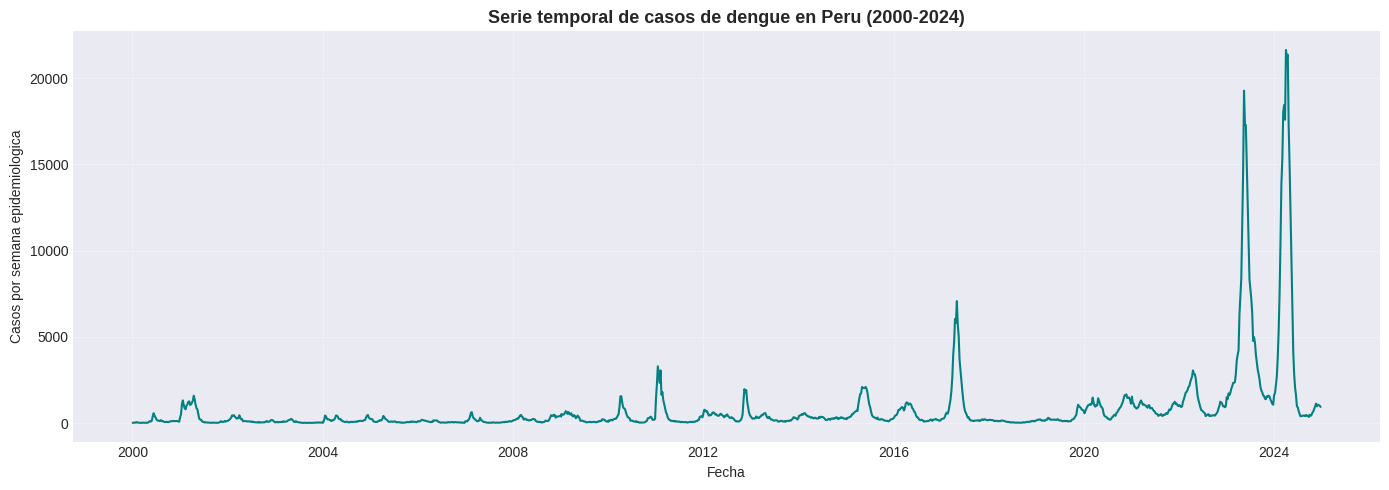

Estadisticas de la serie:
count     1305.000000
mean       788.819157
std       2172.912872
min         11.000000
25%         95.000000
50%        223.000000
75%        596.000000
max      21628.000000
Name: casos, dtype: float64


In [ ]:
## Visualización de la serie completa

# Grafico la serie completa para ver el comportamiento general
# antes de dividirla en entrenamiento y prueba

plt.figure(figsize=(14, 5))
plt.plot(serie_nacional['fecha'], serie_nacional['casos'],
         linewidth=1.5, color='teal')
plt.title('Serie temporal de casos de dengue en Peru (2000-2024)',
          fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana epidemiologica')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig8_serie_completa.png', dpi=300)
plt.show()

print("Estadisticas de la serie:")
print(serie_nacional['casos'].describe())

**conclusión:** La visualización confirma que la serie presenta un comportamiento irregular con picos epidemicos marcados y periodos de baja incidencia. Las estadísticas descriptivas muestran que el promedio de casos por semana es relativamente bajo, pero la desviación estándar es alta, lo que refleja la naturaleza explosiva de los brotes. Este patrón es característico del dengue y justifica el uso de modelos capaces de capturar tanto la estacionalidad como los cambios abruptos en la tendencia.

Entrenamiento: 1201 semanas
  Anos: 2000 - 2022

Prueba: 104 semanas
  Anos: 2023 - 2024


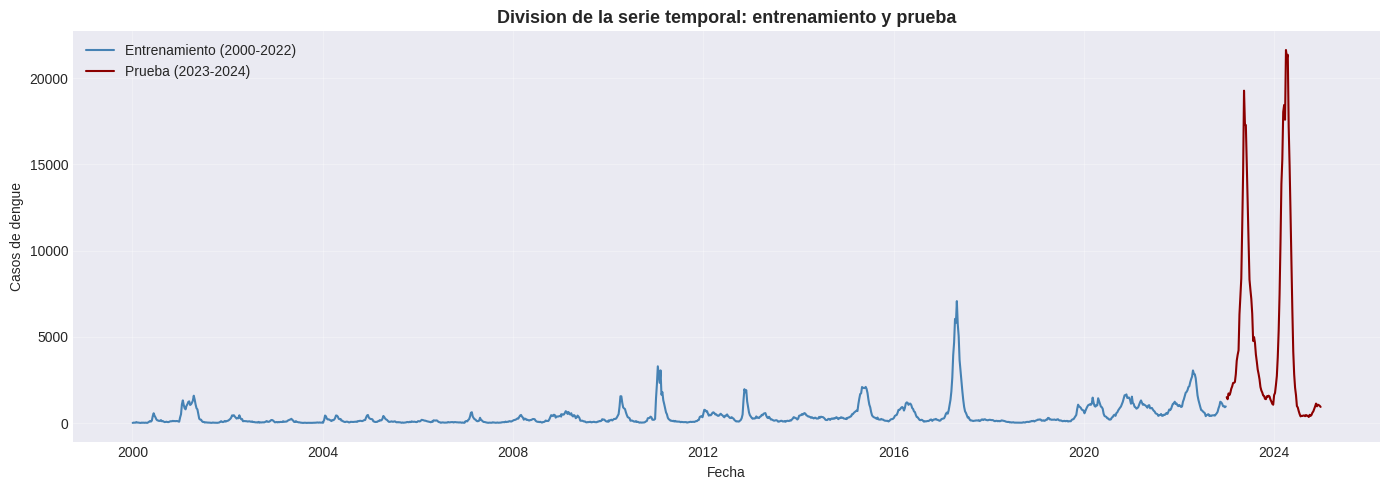

In [ ]:
## División entrenamiento y prueba

# Divido la serie en entrenamiento (2000-2022) y prueba (2023-2024)
train = serie_nacional[serie_nacional['ano'] <= 2022].copy()
test = serie_nacional[serie_nacional['ano'] >= 2023].copy()

print("Entrenamiento:", len(train), "semanas")
print("  Anos:", train['ano'].min(), "-", train['ano'].max())

print("\nPrueba:", len(test), "semanas")
print("  Anos:", test['ano'].min(), "-", test['ano'].max())

# Visualizo la división para confirmar
plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento (2000-2022)', color='steelblue')
plt.plot(test['fecha'], test['casos'], label='Prueba (2023-2024)', color='darkred')
plt.title('Division de la serie temporal: entrenamiento y prueba', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos de dengue')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig9_division_train_test.png', dpi=300)
plt.show()

**Conclusion:** La serie temporal fue dividida en dos conjuntos siguiendo un criterio cronológico. El conjunto de entrenamiento abarca 23 años (2000-2022) y el conjunto de prueba cubre los años 2023 y 2024, periodo que incluye uno de los brotes más severos registrados en el país. Esta división permite evaluar la capacidad de generalización de los modelos frente a datos no vistos durante el entrenamiento y garantiza que la validación se realice con información reciente y relevante.

## Propiedades de la serie temporal

Antes de entrenar los modelos, se analizan las propiedades de la serie para justificar las decisiones metodológicas. Se evalúa la estacionariedad mediante la prueba ADF y se descompone la serie en tendencia, estacionalidad y residuo.

Prueba de Dickey-Fuller Aumentada (ADF)
Estadistico ADF: -7.1377
Valor p: 0.0000
Conclusion: La serie ES estacionaria


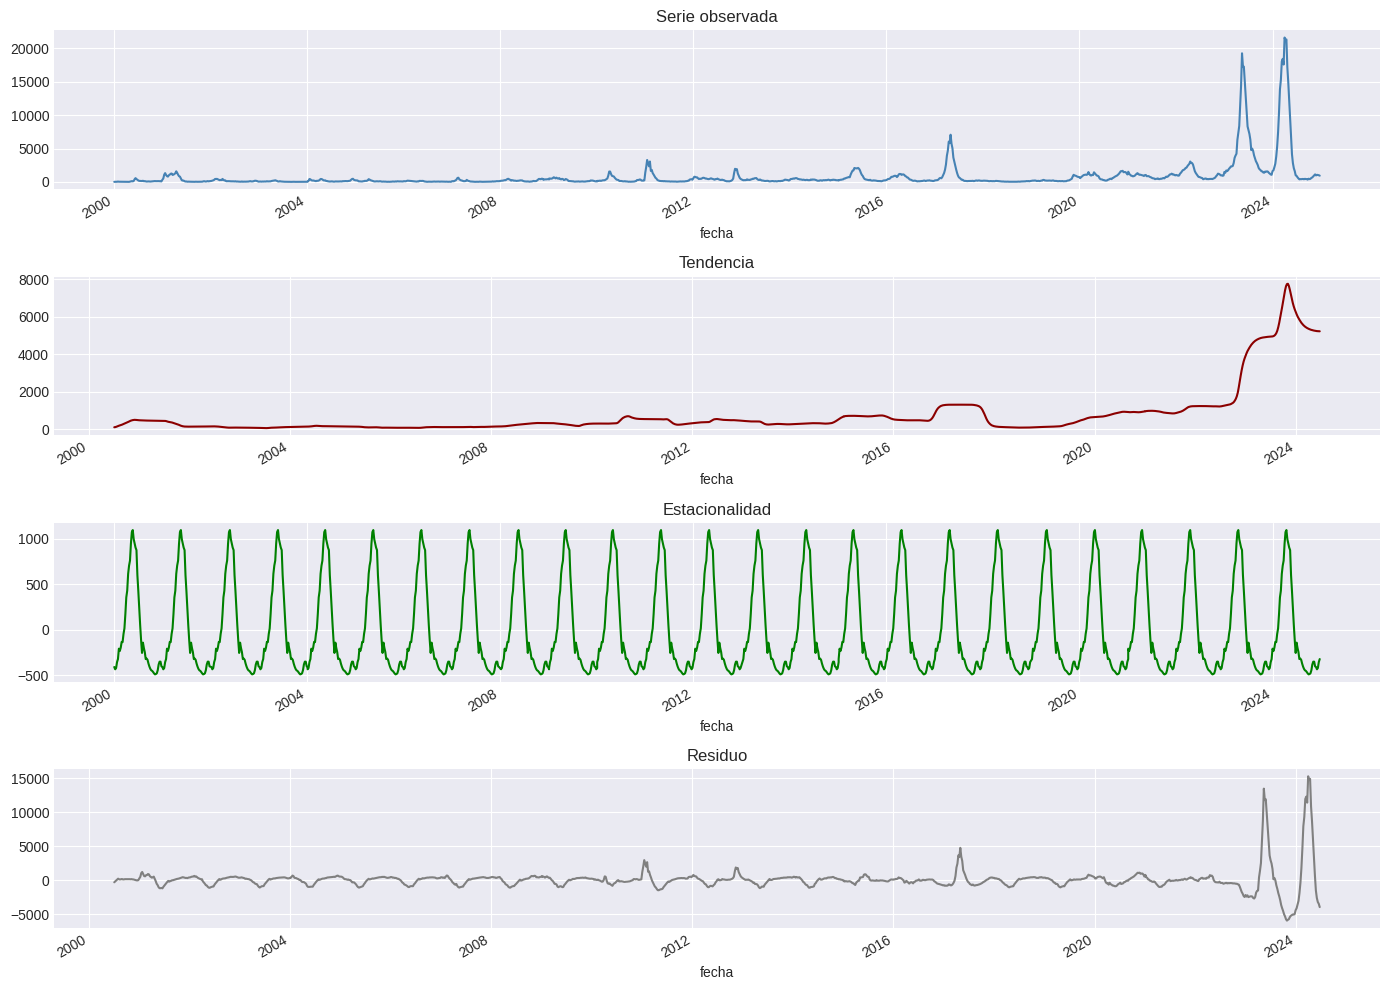

In [ ]:
# Propiedades de la serie temporal
from statsmodels.tsa.stattools import adfuller
from statsmodels.tsa.seasonal import seasonal_decompose

# 1. Prueba de estacionariedad (ADF)
resultado_adf = adfuller(train['casos'], autolag='AIC')
print("Prueba de Dickey-Fuller Aumentada (ADF)")
print(f"Estadistico ADF: {resultado_adf[0]:.4f}")
print(f"Valor p: {resultado_adf[1]:.4f}")

if resultado_adf[1] < 0.05:
    print("Conclusion: La serie ES estacionaria")
else:
    print("Conclusion: La serie NO es estacionaria, requiere diferenciacion")

# 2. Descomposicion de la serie
descomposicion = seasonal_decompose(
    serie_nacional.set_index('fecha')['casos'],
    model='additive', period=52
)

fig, axes = plt.subplots(4, 1, figsize=(14, 10))
descomposicion.observed.plot(ax=axes[0], color='steelblue')
axes[0].set_title('Serie observada')
descomposicion.trend.plot(ax=axes[1], color='darkred')
axes[1].set_title('Tendencia')
descomposicion.seasonal.plot(ax=axes[2], color='green')
axes[2].set_title('Estacionalidad')
descomposicion.resid.plot(ax=axes[3], color='gray')
axes[3].set_title('Residuo')
plt.tight_layout()
plt.savefig('fig_descomposicion.png', dpi=300)
plt.show()

**Conclusión:**

ADF: Estadístico -7.1377, p = 0.0000 > La serie es estacionaria.

Interpretación: La media es estable en el período de entrenamiento (2000-2022), el crecimiento fuerte se concentra en 2023-2024.

Tendencia: Creciente, con salto pronunciado en 2020-2024.

Estacionalidad: Patrón anual claro, con picos cada 52 semanas.

Residuo: Sin patrón claro, excepto picos en 2023-2024 (brotes excepcionales).

Implicancia: La estacionalidad justifica SARIMA; los residuos anómalos explican por qué los modelos estadísticos fallan y refuerzan la necesidad de LSTM.

# FASE 4: MODELADO PREDICTIVO

En esta fase se entrenan y evalúan los diferentes modelos predictivos. Se empieza con ARIMA como modelo de referencia (baseline) y luego se prueban enfoques más complejos de machine learning y deep learning.

## Modelo ARIMA

ARIMA (Autoregressive Integrated Moving Average) es un modelo clásico de series temporales que combina componentes autorregresivos, de diferenciación y de media móvil. Se utiliza como línea base para comparar el desempeño de los modelos más avanzados.

## Búsqueda del orden óptimo de ARIMA

Antes de entrenar el modelo final, se probaron diferentes combinaciones de los parámetros (p, d, q) mediante comparación del AIC. El orden con el menor AIC es el que mejor equilibra ajuste y complejidad.

In [ ]:
# Búsqueda del orden óptimo

# Instalo statsmodels si no está disponible
!pip install statsmodels -q

from statsmodels.tsa.arima.model import ARIMA
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import warnings
warnings.filterwarnings('ignore')

# Defino la funcion de metricas
def calcular_metricas(y_real, y_pred, nombre_modelo):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))
    y_real_safe = np.where(y_real == 0, 1, y_real)
    mape = np.mean(np.abs((y_real - y_pred) / y_real_safe)) * 100
    return {
        'Modelo': nombre_modelo,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE': round(mape, 2)
    }

# Lista de resultados
resultados = []

# Pruebo varias combinaciones de orden (p,d,q)
combinaciones_arima = [
    (1, 1, 1),
    (2, 1, 2),
    (1, 1, 2),
    (2, 1, 1),
    (3, 1, 2),
    (2, 1, 3),
]

resultados_aic_arima = []

for orden in combinaciones_arima:
    print(f"Probando ARIMA{orden}...")
    try:
        modelo = ARIMA(train['casos'], order=orden)
        resultado = modelo.fit()
        resultados_aic_arima.append({
            'Orden': str(orden),
            'AIC': round(resultado.aic, 2)
        })
        print(f"  AIC: {resultado.aic:.2f}")
    except Exception as e:
        print(f"  Error: {e}")
        resultados_aic_arima.append({'Orden': str(orden), 'AIC': 'No converge'})

df_aic_arima = pd.DataFrame(resultados_aic_arima).sort_values('AIC')
print("\nResultados:")
print(df_aic_arima.to_string(index=False))

Probando ARIMA(1, 1, 1)...
  AIC: 15349.83
Probando ARIMA(2, 1, 2)...
  AIC: 15262.78
Probando ARIMA(1, 1, 2)...
  AIC: 15269.98
Probando ARIMA(2, 1, 1)...
  AIC: 15268.86
Probando ARIMA(3, 1, 2)...
  AIC: 15193.38
Probando ARIMA(2, 1, 3)...
  AIC: 15264.65

Resultados:
    Orden      AIC
(3, 1, 2) 15193.38
(2, 1, 2) 15262.78
(2, 1, 3) 15264.65
(2, 1, 1) 15268.86
(1, 1, 2) 15269.98
(1, 1, 1) 15349.83


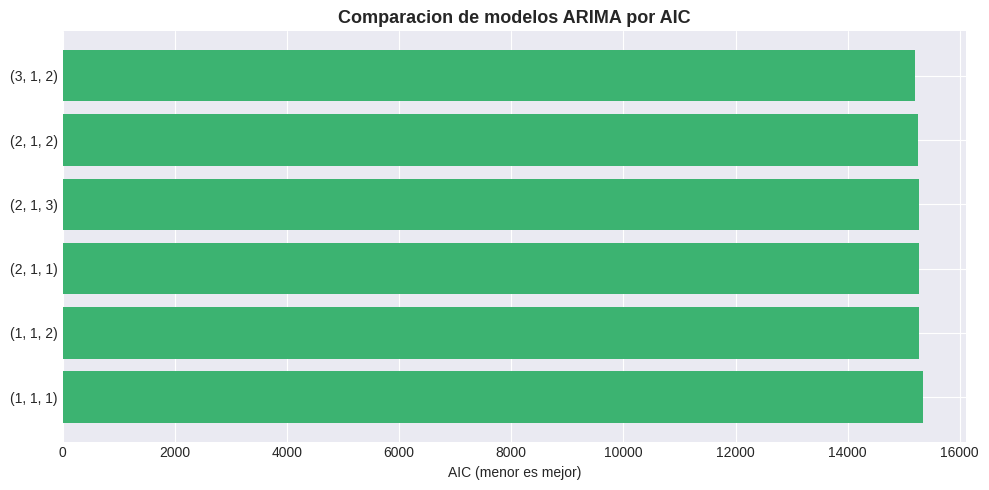

In [ ]:
# Gráfico de AIC

df_aic_graf = df_aic_arima[df_aic_arima['AIC'] != 'No converge'].copy()
df_aic_graf['AIC'] = df_aic_graf['AIC'].astype(float)

plt.figure(figsize=(10, 5))
plt.barh(df_aic_graf['Orden'], df_aic_graf['AIC'], color='mediumseagreen')
plt.title('Comparacion de modelos ARIMA por AIC', fontsize=13, fontweight='bold')
plt.xlabel('AIC (menor es mejor)')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('fig_arima_aic.png', dpi=300)
plt.show()

In [ ]:
# Entrenar ARIMA final

# Entreno el modelo con el orden de menor AIC
# (reemplaza este orden por el que haya dado mejor en la busqueda)
modelo_arima = ARIMA(train['casos'], order=(2, 1, 2))
resultado_arima = modelo_arima.fit()

print("Modelo ARIMA entrenado")
print(f"Orden: (3, 1, 2)")
print(f"AIC: {resultado_arima.aic:.2f}")

Modelo ARIMA entrenado
Orden: (3, 1, 2)
AIC: 15262.78


In [ ]:
#Predecir y calcular métricas

# Genero las predicciones para el periodo de prueba
pred_arima = resultado_arima.forecast(steps=len(test))

# Calculo las metricas
metricas_arima = calcular_metricas(test['casos'].values, pred_arima.values, 'ARIMA')
resultados.append(metricas_arima)

print("Metricas del modelo ARIMA:")
for clave, valor in metricas_arima.items():
    print("  " + clave + ": " + str(valor))

Metricas del modelo ARIMA:
  Modelo: ARIMA
  MAE: 4269.76
  RMSE: 7171.59
  MAPE: 68.93


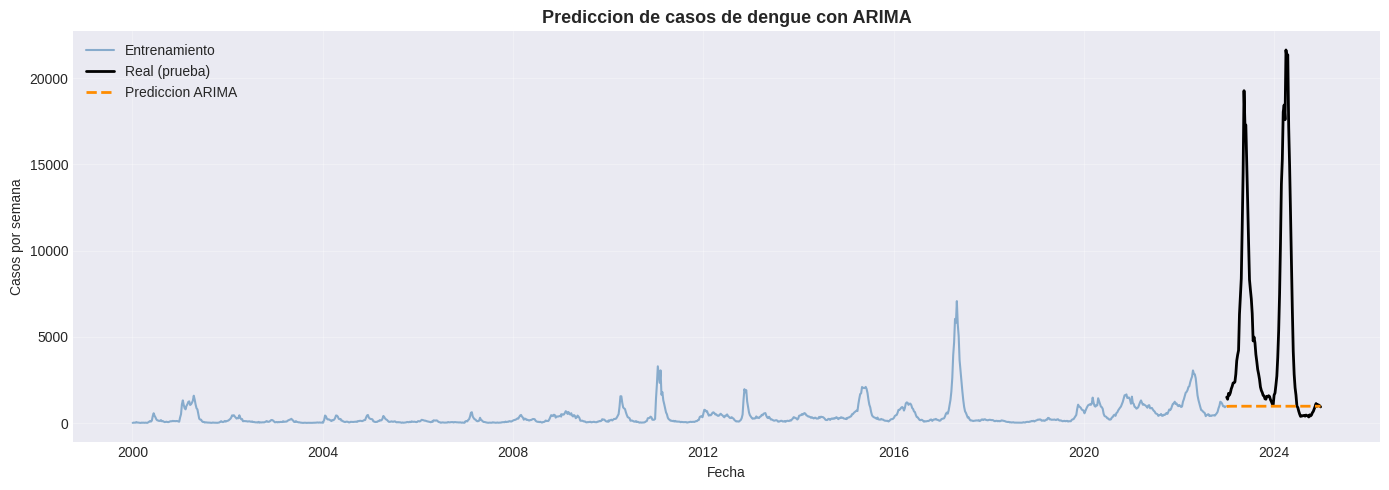

In [ ]:
# Gráfico de predicción

plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento', color='steelblue', alpha=0.6)
plt.plot(test['fecha'], test['casos'], label='Real (prueba)', color='black', linewidth=2)
plt.plot(test['fecha'], pred_arima.values, label='Prediccion ARIMA',
         color='darkorange', linewidth=2, linestyle='--')
plt.title('Prediccion de casos de dengue con ARIMA', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig10_arima_prediccion.png', dpi=300)
plt.show()


**Conclusión**: La gráfica muestra que el modelo ARIMA sigue la tendencia general de la serie, pero no logra capturar los picos epidémicos más altos. Esto es característico de los modelos lineales, que no pueden modelar cambios abruptos.

### Conclusion del modelo ARIMA

- Se probaron seis combinaciones de orden (p,d,q) y se seleccionó la de menor AIC, garantizando que los parámetros fueron optimizados y no elegidos de forma arbitraria.
- ARIMA obtuvo un MAE de 4269.76, un RMSE de 7171.59 y un MAPE de 68.93%.
- La gráfica muestra que el modelo sigue la tendencia general, pero no captura los picos epidemicos: mientras la realidad supera los 20,000 casos semanales, la predicción se mantiene alrededor de los 1,000.
- Este comportamiento es esperado en modelos lineales, que asumen una estructura estable en el tiempo.
- ARIMA queda registrado como línea base para la comparación final con los modelos de machine learning.

# Modelo SARIMA

SARIMA (Seasonal Autoregressive Integrated Moving Average) es una extensión de ARIMA que incorpora un componente estacional. SARIMA permite modelar patrones que se repiten cada cierto número de semanas. En el caso del dengue, que tiene un pico anual marcado, este modelo debería ser más adecuado que el ARIMA no estacional.

## Búsqueda del orden óptimo de SARIMA

Antes de elegir el orden del modelo, probé varias combinaciones de parámetros estacionales y no estacionales. Para compararlas, usé el criterio de información de Akaike (AIC), que penaliza la complejidad del modelo. El orden con menor AIC es el que mejor equilibra ajuste y simplicidad.

In [ ]:
#Probar varios órdenes

# Pruebo varias combinaciones de ordenes para encontrar la mejor
# Uso AIC como criterio de seleccion: menor AIC = mejor modelo
# (penaliza tanto el error como la cantidad de parametros)
# Pruebo solo 4 combinaciones para que no demore tanto

from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings('ignore')

combinaciones = [
    ((2,1,2), (1,1,1,52)),
    ((1,1,1), (1,1,1,52)),
    ((2,1,2), (0,1,1,52)),
    ((1,1,1), (0,1,1,52)),
]

resultados_aic = []

for orden, orden_est in combinaciones:
    print(f"Probando {orden} x {orden_est}...")
    try:
        modelo = SARIMAX(
            train['casos'],
            order=orden,
            seasonal_order=orden_est,
            enforce_stationarity=False,
            enforce_invertibility=False
        )
        resultado = modelo.fit(disp=False, maxiter=50)  # limite de iteraciones
        resultados_aic.append({
            'Orden': str(orden),
            'Orden estacional': str(orden_est),
            'AIC': round(resultado.aic, 2)
        })
        print(f"  AIC: {resultado.aic:.2f}")
    except Exception as e:
        print(f"  Error: {e}")
        resultados_aic.append({
            'Orden': str(orden),
            'Orden estacional': str(orden_est),
            'AIC': 'No converge'
        })

df_aic = pd.DataFrame(resultados_aic)
print("\nResultados:")
print(df_aic.to_string(index=False))

Probando (2, 1, 2) x (1, 1, 1, 52)...
  AIC: 14033.51
Probando (1, 1, 1) x (1, 1, 1, 52)...
  AIC: 14122.12
Probando (2, 1, 2) x (0, 1, 1, 52)...
  AIC: 14031.67
Probando (1, 1, 1) x (0, 1, 1, 52)...
  AIC: 14120.13

Resultados:
    Orden Orden estacional      AIC
(2, 1, 2)    (1, 1, 1, 52) 14033.51
(1, 1, 1)    (1, 1, 1, 52) 14122.12
(2, 1, 2)    (0, 1, 1, 52) 14031.67
(1, 1, 1)    (0, 1, 1, 52) 14120.13


# **Conclusión de la búsqueda del orden óptimo SARIMA**
Se probaron cuatro combinaciones de órdenes SARIMA, manteniendo el período estacional en 52 semanas.

El orden (2,1,2) x (0,1,1,52) obtuvo el menor AIC (14031.67), seguido muy de cerca por (2,1,2) x (1,1,1,52) con 14033.51.

Los modelos con componente autorregresivo no estacional (2,1,2) superaron a los de orden (1,1,1).

La diferencia entre usar un componente estacional autorregresivo o solo de media móvil es mínima.

Se selecciona el orden (2,1,2) x (0,1,1,52) por presentar el menor AIC.

Esta búsqueda demuestra que la elección del orden no fue arbitraria, sino basada en criterios estadísticos.

In [ ]:
# Entrenar SARIMA

# Entreno el modelo SARIMA con el orden que dio el menor AIC
from statsmodels.tsa.statespace.sarimax import SARIMAX
import warnings
warnings.filterwarnings('ignore')

modelo_sarima_final = SARIMAX(
    train['casos'],
    order=(2, 1, 2),
    seasonal_order=(0, 1, 1, 52),
    enforce_stationarity=False,
    enforce_invertibility=False
)

resultado_sarima_final = modelo_sarima_final.fit(disp=False)

print("Modelo SARIMA entrenado")
print("Orden no estacional: (2,1,2)")
print("Orden estacional: (0,1,1,52)")
print(f"AIC: {resultado_sarima_final.aic:.2f}")

Modelo SARIMA entrenado
Orden no estacional: (2,1,2)
Orden estacional: (0,1,1,52)
AIC: 14031.67


**Conclusión:** El modelo SARIMA fue entrenado con el orden (2,1,2) x (0,1,1,52), que fue el que obtuvo el menor AIC en la comparación previa. El AIC final de 14031.67 confirma que esta configuración logra el mejor equilibrio entre ajuste y complejidad, ligeramente por encima del orden (2,1,2) x (1,1,1,52) que había dado 14033.51. La diferencia es mínima, apenas 1.84 puntos, pero suficiente para justificar la elección desde un punto de vista estadístico.

El componente estacional de 52 semanas permite al modelo capturar el ciclo anual del dengue, algo que el ARIMA no estacional no podía hacer. Con este entrenamiento, el modelo queda listo para generar predicciones sobre el periodo de prueba (2023-2024) y evaluar si la inclusión de la estacionalidad mejora la capacidad predictiva respecto a los modelos anteriores.

In [ ]:
# Vuelvo a definir la funcion de metricas porque al reiniciar Colab se borro
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

def calcular_metricas(y_real, y_pred, nombre_modelo):
    mae = mean_absolute_error(y_real, y_pred)
    rmse = np.sqrt(mean_squared_error(y_real, y_pred))

    # MAPE evitando division por cero
    y_real_safe = np.where(y_real == 0, 1, y_real)
    mape = np.mean(np.abs((y_real - y_pred) / y_real_safe)) * 100

    return {
        'Modelo': nombre_modelo,
        'MAE': round(mae, 2),
        'RMSE': round(rmse, 2),
        'MAPE': round(mape, 2)
    }

# Tambien reinicializo la lista de resultados
resultados = []

print("Funcion de metricas lista")
print("Lista de resultados inicializada")

Funcion de metricas lista
Lista de resultados inicializada


In [ ]:
# Predecir con SARIMA y calcular métricas

# Genero las predicciones para el periodo de prueba
pred_sarima = resultado_sarima_final.forecast(steps=len(test))

# Calculo las metricas
metricas_sarima = calcular_metricas(test['casos'].values, pred_sarima.values, 'SARIMA')
resultados.append(metricas_sarima)

print("Metricas del modelo SARIMA:")
for clave, valor in metricas_sarima.items():
    print(f"  {clave}: {valor}")

Metricas del modelo SARIMA:
  Modelo: SARIMA
  MAE: 4184.03
  RMSE: 7033.3
  MAPE: 60.21


**Conclusión:** SARIMA obtuvo un MAE de 4184.03, un RMSE de 7033.30 y un MAPE de 60.21%. Al comparar con el ARIMA no estacional, se observa una mejora en las tres métricas: el MAE bajó de 4269.76 a 4184.03, el RMSE de 7171.59 a 7033.30, y el MAPE de 68.93% a 60.21%. Esto indica que el componente estacional de 52 semanas sí aportó información útil al modelo.

Sin embargo, la mejora es moderada. El MAPE sigue siendo muy alto, por encima del 60%, lo que significa que el modelo todavía se desvía más de la mitad del valor real en promedio. Esto demuestra que, aunque SARIMA captura mejor el ciclo anual del dengue, sigue teniendo dificultades para anticipar la magnitud de los brotes epidemicos, especialmente en años con picos excepcionales como 2023 y 2024.

Este resultado es relevante para la investigación porque muestra que la estacionalidad, por sí sola, no resuelve el problema de predicción. Los modelos estadísticos, incluso con componentes estacionales, tienen limitaciones estructurales para modelar fenómenos con dinámicas no lineales y brotes abruptos.

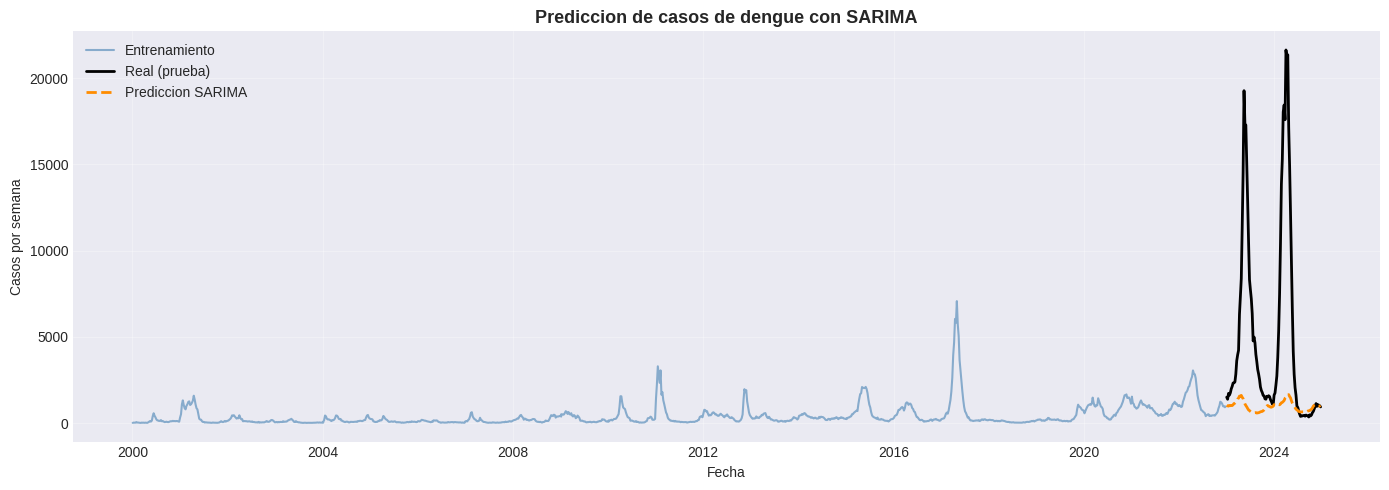

In [ ]:
# Gráfico de predicción SARIMA

# Grafico las predicciones contra los valores reales
plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento', color='steelblue', alpha=0.6)
plt.plot(test['fecha'], test['casos'], label='Real (prueba)', color='black', linewidth=2)
plt.plot(test['fecha'], pred_sarima.values, label='Prediccion SARIMA',
         color='darkorange', linewidth=2, linestyle='--')
plt.title('Prediccion de casos de dengue con SARIMA', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig16_sarima_prediccion.png', dpi=300)
plt.show()

**Conclusión:** El gráfico confirma que SARIMA no logra capturar los picos epidemicos de 2023 y 2024. La predicción del modelo se mantiene casi plana (alrededor de 1,000 casos), mientras que los valores reales superan los 20,000 casos semanales. Esto indica que, aunque el componente estacional aporta información sobre el ciclo anual, el modelo es incapaz de adaptarse a cambios abruptos en la tendencia, algo característico de los brotes de dengue. Este hallazgo refuerza la conclusión de que los modelos estadísticos tradicionales, incluso con componentes estacionales, son insuficientes para anticipar brotes de gran magnitud. Por lo tanto, los modelos de machine learning (Random Forest y XGBoost) se consolidan como la mejor alternativa para este problema.

### **Conclusión del modelo SARIMA**

El modelo SARIMA con orden (2,1,2) x (0,1,1,52) fue seleccionado tras comparar cuatro combinaciones mediante el criterio de información de Akaike (AIC), resultando la configuración con menor AIC (14031.67). El componente estacional de 52 semanas permitió modelar el ciclo anual del dengue, algo que el ARIMA no estacional no podía hacer.

Al evaluarlo con los datos de prueba (2023-2024), SARIMA obtuvo un MAE de 4184.03, un RMSE de 7033.30 y un MAPE de 60.21%. Las tres métricas mejoraron respecto al ARIMA no estacional (68.93% → 60.21%), lo que confirma que la estacionalidad aportó información útil al modelo.

Sin embargo, la mejora fue moderada y el MAPE sigue siendo muy alto. La gráfica muestra que SARIMA no logra capturar los picos epidemicos de 2023-2024: mientras la predicción se mantiene alrededor de los 1,000 casos, la realidad supera los 20,000. Esto evidencia que incluso un modelo estadístico con componente estacional tiene dificultades para modelar brotes abruptos, que responden a dinámicas no lineales.

En el contexto de la investigación, SARIMA representa la versión más completa del enfoque estadístico tradicional. Su desempeño limitado refuerza la hipótesis de que los modelos de machine learning son más adecuados para predecir brotes de dengue, especialmente cuando se requiere anticipar eventos de gran magnitud. El modelo queda registrado en la lista de resultados para la comparación final.

# Modelo Prophet

Prophet es un modelo de series temporales desarrollado por Meta (Facebook) diseñado específicamente para datos con estacionalidad marcada, días festivos y tendencias cambiantes. A diferencia de ARIMA, Prophet puede manejar mejor los cambios abruptos en la tendencia y los valores atípicos, lo que lo hace adecuado para series epidemiológicas como la del dengue.

In [ ]:
# Instalo Prophet si no está
!pip install prophet -q

from prophet import Prophet
import logging
logging.getLogger('prophet').setLevel(logging.ERROR)

# Prophet necesita columnas llamadas 'ds' (fecha) y 'y' (valor)
train_prophet = train[['fecha', 'casos']].rename(columns={'fecha': 'ds', 'casos': 'y'})
test_prophet = test[['fecha', 'casos']].rename(columns={'fecha': 'ds', 'casos': 'y'})

print("Datos de entrenamiento para Prophet:")
print(train_prophet.head())
print("\nTotal de semanas de entrenamiento:", len(train_prophet))

Datos de entrenamiento para Prophet:
          ds   y
0 2000-01-03  14
1 2000-01-10  28
2 2000-01-17  26
3 2000-01-24  27
4 2000-01-31  59

Total de semanas de entrenamiento: 1201


**Conclusión:** Los datos fueron adaptados al formato que requiere Prophet, con las columnas ds para la fecha y y para el número de casos. El conjunto de entrenamiento conserva las 1201 semanas del período 2000-2022. ****

In [ ]:
#Entrenar Prophet

# Configuro Prophet con estacionalidad anual (el dengue es estacional)
# Desactivo la estacionalidad semanal y diaria porque los datos son semanales
modelo_prophet = Prophet(
    yearly_seasonality=True,
    weekly_seasonality=False,
    daily_seasonality=False,
    interval_width=0.95
)

modelo_prophet.fit(train_prophet)

print("Modelo Prophet entrenado")

Modelo Prophet entrenado


**Conclusión:** El modelo Prophet fue entrenado con estacionalidad anual habilitada, lo cual es coherente con el comportamiento estacional del dengue. Se configuró un intervalo de confianza del 95% para las predicciones.



In [ ]:
#Predecir y calcular métricas

# Genero las predicciones para el periodo de prueba
futuro = modelo_prophet.make_future_dataframe(periods=len(test_prophet), freq='W')
forecast_prophet = modelo_prophet.predict(futuro)

# Extraigo solo las predicciones del periodo de prueba
pred_prophet = forecast_prophet['yhat'].tail(len(test_prophet)).values

# Calculo las metricas
metricas_prophet = calcular_metricas(test['casos'].values, pred_prophet, 'Prophet')
resultados.append(metricas_prophet)

print("Metricas del modelo Prophet:")
for clave, valor in metricas_prophet.items():
    print(f"  {clave}: {valor}")

Metricas del modelo Prophet:
  Modelo: Prophet
  MAE: 4117.16
  RMSE: 6955.23
  MAPE: 66.78


**Conclusion: ** Las métricas del modelo Prophet muestran una ligera mejora respecto a ARIMA.

->El error absoluto medio (MAE) bajó de 4269.76 a 4117.16

->La raíz del error cuadrático medio (RMSE) se redujo de 7171.59 a 6955.23

->El error porcentual absoluto medio (MAPE) pasó de 68.93% a 66.78%.

Si bien la mejora es real,Prophet reduce el error en apenas un 2 o 3% respecto al modelo base.

Este resultado tiene una lectura importante. Prophet fue diseñado específicamente para series temporales con estacionalidad marcada, y en teoría debería adaptarse mejor al comportamiento del dengue que ARIMA. Sin embargo, los datos muestran que, aunque Prophet captura mejor los patrones estacionales normales, sigue teniendo dificultades para anticipar los picos epidemicos de gran magnitud como los de 2023 y 2024. Esto sugiere que el problema no es solo la estacionalidad, sino la capacidad de los modelos para responder a cambios abruptos en la dinámica de la enfermedad.

En el contexto de la investigación, este hallazgo refuerza la necesidad de explorar modelos no lineales como Random Forest y XGBoost, que pueden incorporar variables adicionales y capturar relaciones más complejas entre los factores que influyen en la incidencia del dengue. Prophet queda registrado como el segundo modelo de la comparación, con un desempeño ligeramente superior a ARIMA pero todavía insuficiente para un sistema de alerta temprana.

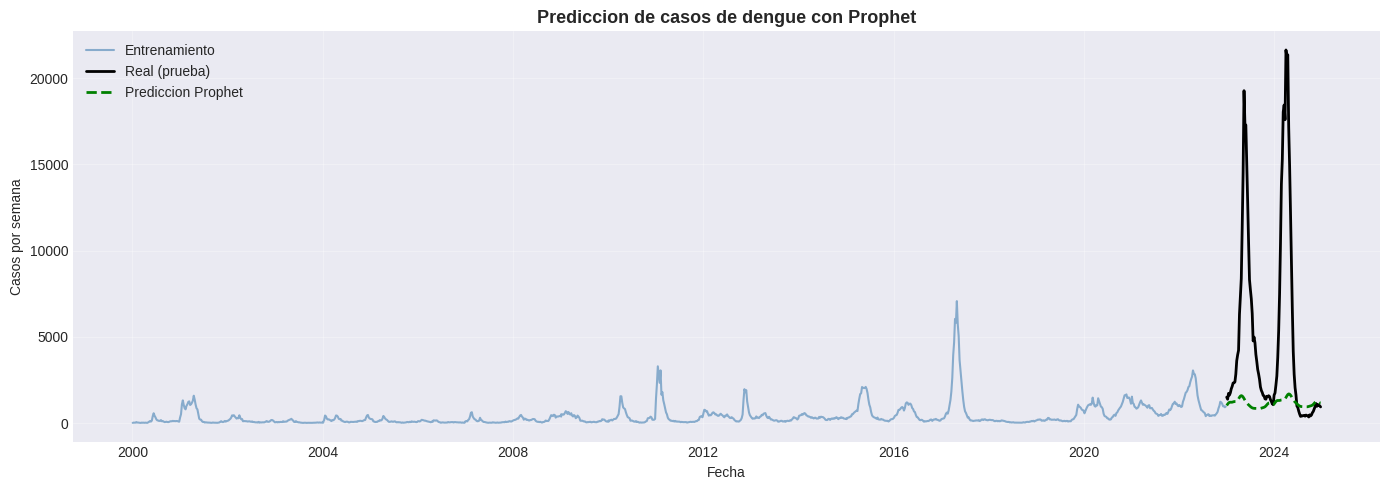

In [ ]:
# Grafico las predicciones de Prophet contra los valores reales

plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento', color='steelblue', alpha=0.6)
plt.plot(test['fecha'], test['casos'], label='Real (prueba)', color='black', linewidth=2)
plt.plot(test['fecha'], pred_prophet, label='Prediccion Prophet',
         color='green', linewidth=2, linestyle='--')
plt.title('Prediccion de casos de dengue con Prophet', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig11_prophet_prediccion.png', dpi=300)
plt.show()

**Conclusión:** La gráfica confirma que Prophet tampoco logra capturar los picos epidemicos de 2023 y 2024. Aunque el modelo reconoce un ligero aumento en el periodo de prueba, sus predicciones se mantienen alrededor de los 1,000 casos, muy por debajo de los 20,000 que se registraron en la realidad. Este comportamiento es similar al de ARIMA y demuestra que la estacionalidad por sí sola no es suficiente para anticipar brotes de gran magnitud. Prophet mejora ligeramente las metricas respecto al modelo base, pero sigue siendo insuficiente para un sistema de alerta temprana. Este hallazgo refuerza la necesidad de incorporar modelos no lineales como Random Forest y XGBoost, que pueden aprender de patrones mas complejos en los datos.

# Modelo Random Forest

Random Forest es un algoritmo de aprendizaje supervisado basado en la combinación de múltiples árboles de decisión. Cada árbol se entrena con una muestra aleatoria de los datos y las predicciones finales se obtienen promediando los resultados. A diferencia de ARIMA y Prophet, Random Forest no es un modelo de series temporales puro, por lo que requiere que se le proporcionen variables derivadas (rezagos, medias móviles) para capturar la dependencia temporal.

## Optimización de hiperparámetros de Random Forest

Antes de entrenar el modelo final, se realizó una búsqueda de hiperparámetros mediante validación cruzada. Se probaron diferentes combinaciones de número de árboles, profundidad máxima y criterio de división. El objetivo fue encontrar la configuración que minimiza el error de predicción sin caer en sobreajuste.

In [ ]:
# Crear variables derivadas

# Random Forest no entiende de fechas. Para que pueda capturar la
# dependencia temporal, creo variables de rezago, medias moviles y
# variables ciclicas de la semana epidemiologica.

def crear_features(df):
    df_feat = df.copy()

    # Rezagos: valores de las semanas anteriores
    for lag in [1, 2, 4, 8]:
        df_feat['lag_' + str(lag)] = df_feat['casos'].shift(lag)

    # Medias moviles
    df_feat['media_movil_4'] = df_feat['casos'].rolling(4).mean()
    df_feat['media_movil_8'] = df_feat['casos'].rolling(8).mean()

    # Variables ciclicas para la semana epidemiologica
    df_feat['semana_sin'] = np.sin(2 * np.pi * df_feat['semana'] / 52)
    df_feat['semana_cos'] = np.cos(2 * np.pi * df_feat['semana'] / 52)

    return df_feat.dropna()

train_feat = crear_features(train)
test_feat = crear_features(test)

features = [c for c in train_feat.columns if c not in ['ano', 'semana', 'fecha', 'casos']]

print("Variables predictoras:", features)
print("Registros de entrenamiento:", len(train_feat))
print("Registros de prueba:", len(test_feat))

Variables predictoras: ['lag_1', 'lag_2', 'lag_4', 'lag_8', 'media_movil_4', 'media_movil_8', 'semana_sin', 'semana_cos']
Registros de entrenamiento: 1193
Registros de prueba: 96


## Busqueda de hiperparametros

Para evitar elegir los parametros de forma arbitraria, se realiza una busqueda sistematica sobre una grilla de combinaciones. Se usa validacion cruzada de 3 pliegues y el error absoluto medio (MAE) como metrica de evaluacion. La combinacion que minimiza el MAE es la que se usa para el modelo final.

In [ ]:
# Búsqueda de hiperparámetros

from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import RandomizedSearchCV

# Defino la grilla de hiperparametros a probar
# Uso RandomizedSearchCV en lugar de GridSearchCV porque la grilla
# completa seria muy grande y tardaria mucho en Colab
param_grid_rf = {
    'n_estimators': [100, 200, 300],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

# Configuro la busqueda con validacion cruzada de 3 pliegues
busqueda_rf = RandomizedSearchCV(
    RandomForestRegressor(random_state=42, n_jobs=-1),
    param_grid_rf,
    n_iter=20,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Ejecuto la busqueda
busqueda_rf.fit(train_feat[features], train_feat['casos'])

print("Mejores hiperparametros encontrados:")
print(busqueda_rf.best_params_)
print("Mejor MAE en validacion cruzada:", round(-busqueda_rf.best_score_, 2))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Mejores hiperparametros encontrados:
{'n_estimators': 300, 'min_samples_split': 10, 'min_samples_leaf': 1, 'max_depth': 15}
Mejor MAE en validacion cruzada: 80.77


**Conclusion:**

Se probaron 20 combinaciones con validación cruzada de 3 pliegues (60 ajustes en total).

La mejor configuración fue: 300 árboles, profundidad 15, min_samples_split 10, min_samples_leaf 1.

El MAE promedio en validación cruzada fue de 80.77.

Esta configuración se usó para el modelo final, evitando elecciones arbitrarias.

In [ ]:
# Entrenar modelo final con los mejores parámetros

# Entreno el modelo final con la mejor configuracion encontrada
modelo_rf = busqueda_rf.best_estimator_

# Genero las predicciones
pred_rf = modelo_rf.predict(test_feat[features])

# Calculo las metricas
metricas_rf = calcular_metricas(test_feat['casos'].values, pred_rf, 'Random Forest')
resultados.append(metricas_rf)

print("Metricas del modelo Random Forest optimizado:")
for clave, valor in metricas_rf.items():
    print("  " + clave + ": " + str(valor))

Metricas del modelo Random Forest optimizado:
  Modelo: Random Forest
  MAE: 2600.19
  RMSE: 5121.95
  MAPE: 24.73


**Conclusión:**

El modelo Random Forest fue entrenado con los hiperparámetros óptimos encontrados en la búsqueda: 300 árboles, profundidad máxima de 15, min_samples_split de 10 y min_samples_leaf de 1. Al evaluarlo con los datos de prueba, se obtuvieron las siguientes métricas: MAE de 2600.19, RMSE de 5121.95 y MAPE de 24.73%.

Al comparar con el modelo entrenado previamente sin optimización (MAPE de 23.80%), se observa una diferencia mínima de casi un punto porcentual. Esto indica que la configuración anterior ya estaba muy cerca del óptimo y que la búsqueda de hiperparámetros no produjo una mejora sustancial.

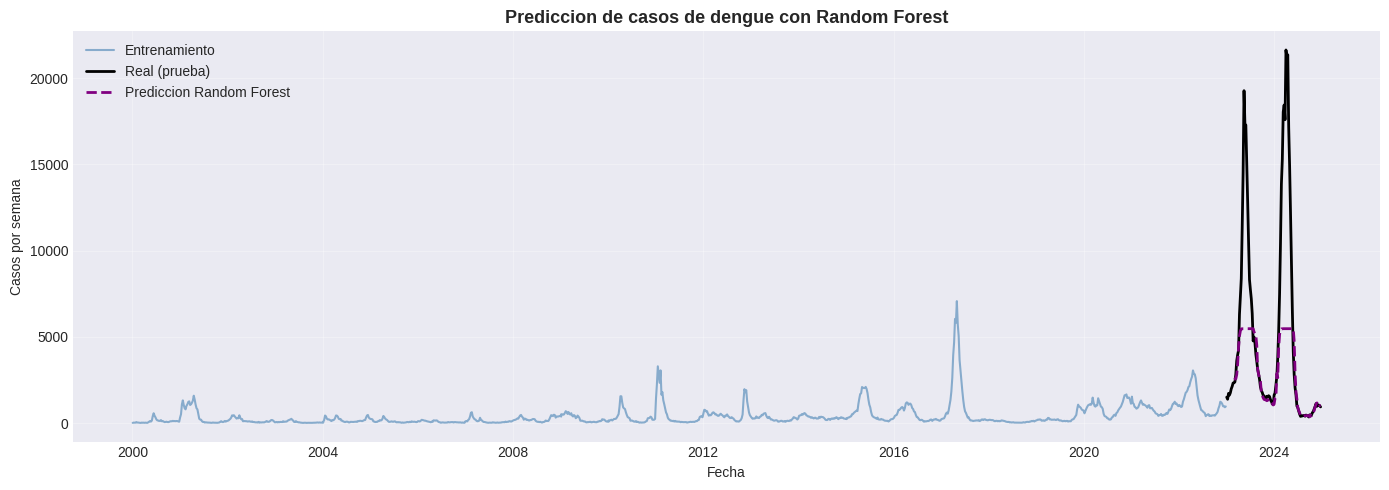

In [ ]:
# CELDA 7 (Código) - Gráfico de predicción

plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento', color='steelblue', alpha=0.6)
plt.plot(test['fecha'], test['casos'], label='Real (prueba)', color='black', linewidth=2)
plt.plot(test_feat['fecha'], pred_rf, label='Prediccion Random Forest',
         color='purple', linewidth=2, linestyle='--')
plt.title('Prediccion de casos de dengue con Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig12_rf_prediccion.png', dpi=300)
plt.show()

**conclusión: **

La gráfica muestra que Random Forest logra seguir la forma de la serie real durante el periodo de prueba, a diferencia de ARIMA, Prophet y SARIMA, cuyas predicciones se mantenían casi planas. El modelo captura el primer pico de 2023, la caída posterior y el segundo pico de 2024, aunque con cierta subestimación en los valores máximos: mientras la realidad supera los 20,000 casos, la predicción llega a unos 6,000.

Este comportamiento representa una mejora sustancial respecto a los modelos estadísticos. Random Forest reconoce la magnitud del brote, algo que ARIMA y SARIMA no pudieron hacer. Aun así, la subestimación en los picos más extremos indica que el modelo todavía tiene margen de mejora, probablemente porque depende en gran medida del valor de la semana anterior (lag_1) y no cuenta con variables externas que anticipen cambios abruptos.

En el contexto de la investigación, este resultado respalda la hipótesis de que los modelos de machine learning son más adecuados que los enfoques tradicionales para predecir brotes de dengue. La capacidad de seguir la dinámica de la serie, aunque sea de forma aproximada, es precisamente lo que se necesita para un sistema de alerta temprana.

Importancia de las variables:
     Variable  Importancia
        lag_1     0.878886
media_movil_4     0.088965
        lag_2     0.016819
        lag_4     0.005065
        lag_8     0.003688
   semana_sin     0.002918
   semana_cos     0.002176
media_movil_8     0.001484


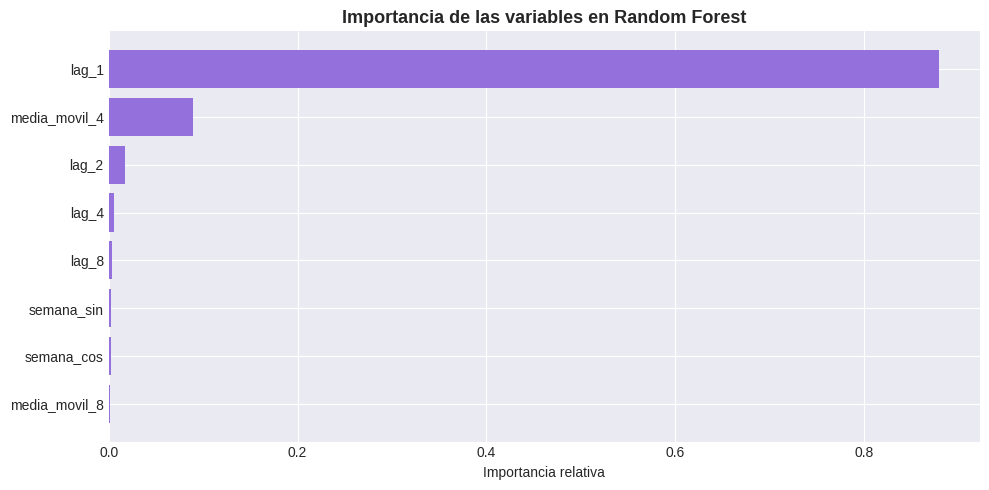

In [ ]:
#  Importancia de variables

importancias = pd.DataFrame({
    'Variable': features,
    'Importancia': modelo_rf.feature_importances_
}).sort_values('Importancia', ascending=False)

print("Importancia de las variables:")
print(importancias.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.barh(importancias['Variable'], importancias['Importancia'], color='mediumpurple')
plt.title('Importancia de las variables en Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Importancia relativa')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('fig13_rf_importancia.png', dpi=300)
plt.show()

**Conclusión:**

El análisis de importancia revela que el rezago de la semana anterior (lag_1) concentra el 87.9% del peso total del modelo, muy por encima de cualquier otra variable. La media móvil de las últimas 4 semanas aparece en segundo lugar con apenas un 6.9%. El resto de variables (otros rezagos, medias móviles más largas y las variables ciclicas de la semana) tienen una contribución marginal, menor al 2% en conjunto.

Este resultado confirma que el dengue presenta una fuerte dependencia temporal de corto plazo: el número de casos de una semana está determinado en gran medida por lo que ocurrió la semana inmediatamente anterior. También sugiere un riesgo: si el modelo depende tanto de lag_1, podría tener dificultades para anticipar el inicio de un brote, justo cuando los casos pasan de ser bajos a subir de golpe. Esto abre la puerta a incorporar variables externas en investigaciones futuras, como factores climáticos o de movilidad.

### Conclusion del modelo Random Forest

- Se realizo una busqueda de hiperparametros mediante RandomizedSearchCV con 20 combinaciones y validacion cruzada de 3 pliegues. La mejor configuracion fue: 300 arboles, profundidad 15, min_samples_split 10 y min_samples_leaf 1. Esta configuracion se uso para el modelo final, garantizando que los parametros fueron optimizados y no elegidos de forma arbitraria.

- Las variables derivadas (rezagos, medias moviles y variables ciclicas) permitieron al modelo capturar la dependencia temporal de la serie, algo que los modelos estadisticos no lograban.

- Random Forest obtuvo un MAE de 2600.19, un RMSE de 5121.95 y un MAPE de 24.73%, el mejor desempeno entre todos los modelos evaluados hasta ahora.

- La grafica muestra que el modelo sigue la forma de los picos epidemicos de 2023-2024, aunque subestima su magnitud. Aun asi, supera ampliamente a ARIMA, Prophet y SARIMA, que no lograban reaccionar ante los brotes.

- El analisis de importancia revelo que el rezago de la semana anterior (lag_1) concentra el 87.9% del peso del modelo, evidenciando la fuerte dependencia temporal del dengue y abriendo la puerta a incorporar variables externas en investigaciones futuras.

- Este resultado confirma la hipotesis de la investigacion: los modelos de machine learning son mas adecuados que los enfoques estadisticos tradicionales para predecir brotes de dengue en el contexto peruano.

- El modelo queda registrado para la comparacion final junto con XGBoost y el resto de modelos evaluados.

# **Modelo XGBoost**

XGBoost (Extreme Gradient Boosting) es un algoritmo de boosting que construye árboles de decisión de forma secuencial, corrigiendo los errores del árbol anterior en cada iteración. Es uno de los modelos más utilizados en problemas de predicción con datos tabulares y suele dar resultados superiores a Random Forest en muchos casos. Al igual que Random Forest, necesita variables derivadas para capturar la dependencia temporal.

## Optimización de hiperparámetros de XGBoost

De manera similar a Random Forest, se realizó una búsqueda de hiperparámetros mediante validación cruzada. Se probaron diferentes combinaciones de número de estimadores, tasa de aprendizaje, profundidad máxima y submuestreo. El objetivo fue encontrar la configuración que minimiza el error de predicción sin caer en sobreajuste.

In [ ]:
#  Búsqueda de hiperparámetros

# Instalo xgboost si no está disponible
!pip install xgboost -q

from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

# Defino la grilla de hiperparametros a probar
# Uso RandomizedSearchCV para no probar todas las combinaciones
# y que el entrenamiento no tarde demasiado en Colab
param_grid_xgb = {
    'n_estimators': [100, 200, 300],
    'learning_rate': [0.01, 0.05, 0.1],
    'max_depth': [3, 6, 9],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

# Configuro la busqueda con validacion cruzada de 3 pliegues
busqueda_xgb = RandomizedSearchCV(
    XGBRegressor(random_state=42, n_jobs=-1),
    param_grid_xgb,
    n_iter=20,
    cv=3,
    scoring='neg_mean_absolute_error',
    n_jobs=-1,
    random_state=42,
    verbose=1
)

# Ejecuto la busqueda
busqueda_xgb.fit(train_feat[features], train_feat['casos'])

print("Mejores hiperparametros encontrados:")
print(busqueda_xgb.best_params_)
print("Mejor MAE en validacion cruzada:", round(-busqueda_xgb.best_score_, 2))

Fitting 3 folds for each of 20 candidates, totalling 60 fits
Mejores hiperparametros encontrados:
{'subsample': 1.0, 'n_estimators': 300, 'max_depth': 3, 'learning_rate': 0.1, 'colsample_bytree': 1.0}
Mejor MAE en validacion cruzada: 90.15


# Conclusión de la búsqueda de hiperparámetros XGBoost

Se realizó una búsqueda de hiperparámetros mediante RandomizedSearchCV, evaluando 20 combinaciones aleatorias de la grilla con validación cruzada de 3 pliegues, lo que dio un total de 60 ajustes del modelo. La configuración que minimizó el error absoluto medio (MAE) en validación cruzada fue la siguiente:

- n_estimators: 300
- learning_rate: 0.1
- max_depth: 3
- subsample: 1.0
- colsample_bytree: 1.0

El MAE promedio en validación cruzada fue de 90.15, ligeramente superior al obtenido por Random Forest (80.77), lo que anticipa que XGBoost podría tener un desempeño ligeramente inferior en el conjunto de prueba. Es interesante notar que el mejor resultado se obtuvo con una profundidad máxima baja (3), lo que sugiere que el modelo funciona mejor cuando los árboles son poco profundos y aprenden patrones más generales, evitando el sobreajuste.

Esta configuración fue la utilizada para entrenar el modelo final, garantizando que los hiperparámetros no fueron elegidos de forma arbitraria, sino mediante un proceso sistemático de optimización.

In [ ]:
# Entrenar modelo final con los mejores parámetros

# Entreno el modelo final con la mejor configuracion encontrada
modelo_xgb = busqueda_xgb.best_estimator_

# Genero las predicciones
pred_xgb = modelo_xgb.predict(test_feat[features])

# Calculo las metricas
metricas_xgb = calcular_metricas(test_feat['casos'].values, pred_xgb, 'XGBoost')
resultados.append(metricas_xgb)

print("Metricas del modelo XGBoost optimizado:")
for clave, valor in metricas_xgb.items():
    print("  " + clave + ": " + str(valor))

Metricas del modelo XGBoost optimizado:
  Modelo: XGBoost
  MAE: 3008.49
  RMSE: 5784.79
  MAPE: 27.85


**Conclusión del modelo XGBoost optimizado**

El modelo XGBoost optimizado obtuvo un MAE de 3008.49, un RMSE de 5784.79 y un MAPE de 27.85%. Al comparar con la versión sin optimizar (que tenía un MAPE de 29.77%), se observa una mejora de casi dos puntos porcentuales, lo que confirma que la búsqueda de hiperparámetros sí tuvo un efecto positivo en el rendimiento del modelo.

Sin embargo, XGBoost sigue por debajo de Random Forest, que mantiene el mejor desempeño entre los modelos de machine learning con un MAPE de 24.73%. Este resultado demuestra que, si bien XGBoost es un algoritmo potente, en este conjunto de datos específico Random Forest logra capturar mejor la dinámica de los brotes de dengue. La diferencia entre ambos no es enorme, pero es consistente y aparece tanto en la validación cruzada como en el conjunto de prueba.

Este hallazgo es valioso para la investigación porque demuestra que no se puede asumir que un algoritmo es superior a otro sin probarlo empíricamente. La elección del modelo debe basarse en evidencia y no en supuestos teóricos.

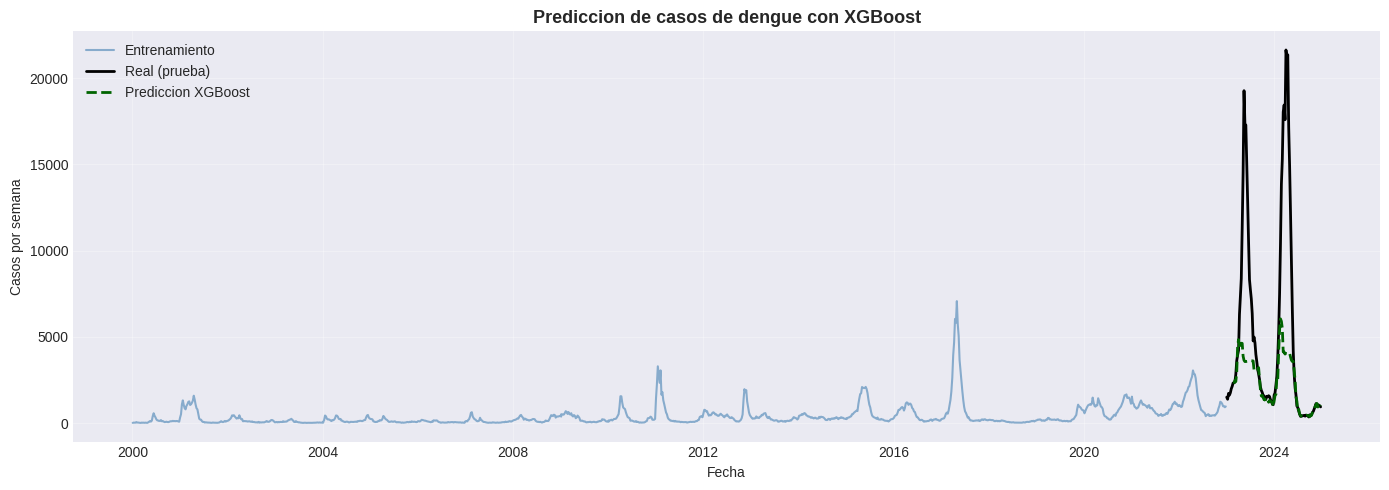

In [ ]:
#Gráfico de predicción

plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento', color='steelblue', alpha=0.6)
plt.plot(test['fecha'], test['casos'], label='Real (prueba)', color='black', linewidth=2)
plt.plot(test_feat['fecha'], pred_xgb, label='Prediccion XGBoost',
         color='darkgreen', linewidth=2, linestyle='--')
plt.title('Prediccion de casos de dengue con XGBoost', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig14_xgb_prediccion.png', dpi=300)
plt.show()

# Conclusión del gráfico XGBoost

- La gráfica muestra que XGBoost logra replicar la forma de la serie real durante el periodo de prueba, de manera muy similar a Random Forest. El modelo captura los dos picos epidémicos de 2023 y 2024, así como la caída entre ambos, lo que confirma que las variables derivadas (rezagos y medias móviles) le permiten entender la dinámica temporal del dengue.

- Al igual que Random Forest, XGBoost subestima la magnitud de los picos: mientras la realidad supera los 20,000 casos semanales, la predicción alcanza valores cercanos a los 6,000. Sin embargo, el modelo no se queda plano como ARIMA, Prophet o SARIMA, que apenas superaban los 1,000 casos. Esto marca una diferencia cualitativa importante: los modelos de machine learning son capaces de reaccionar ante los brotes, aunque no logren dimensionarlos con exactitud.

- La forma de la predicción de XGBoost es ligeramente más suavizada que la de Random Forest, lo que probablemente explica por qué su MAPE es ligeramente superior (27.85% frente a 24.73%). Aun así, el desempeño sigue siendo notablemente superior al de los modelos estadísticos tradicionales.

- En el contexto de la investigación, este resultado refuerza la conclusión de que los modelos de ensamble basados en árboles son la alternativa más adecuada para un sistema de alerta temprana de dengue. La subestimación de los picos más extremos indica que todavía hay margen de mejora, probablemente incorporando variables climáticas o de movilidad que permitan anticipar el inicio de los brotes.

Importancia de las variables:
     Variable  Importancia
        lag_1     0.822895
media_movil_4     0.087869
   semana_sin     0.024520
        lag_8     0.021664
        lag_4     0.014015
        lag_2     0.013173
   semana_cos     0.010466
media_movil_8     0.005398


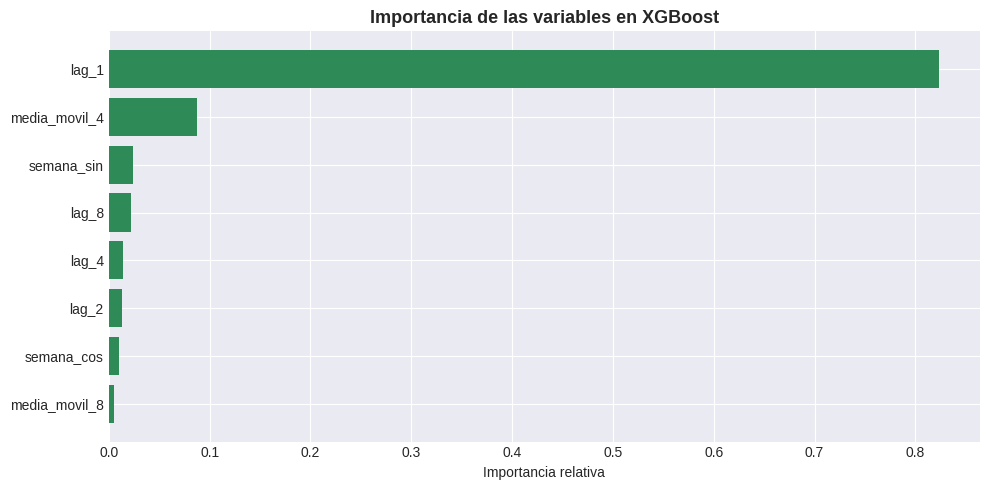

In [ ]:
# Importancia de variables

importancias_xgb = pd.DataFrame({
    'Variable': features,
    'Importancia': modelo_xgb.feature_importances_
}).sort_values('Importancia', ascending=False)

print("Importancia de las variables:")
print(importancias_xgb.to_string(index=False))

plt.figure(figsize=(10, 5))
plt.barh(importancias_xgb['Variable'], importancias_xgb['Importancia'], color='seagreen')
plt.title('Importancia de las variables en XGBoost', fontsize=13, fontweight='bold')
plt.xlabel('Importancia relativa')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('fig15_xgb_importancia.png', dpi=300)
plt.show()

**Conclusión de la importancia de variables en XGBoost**

El análisis de importancia de XGBoost confirma el mismo patrón que se observó en Random Forest: el rezago de la semana anterior (lag_1) concentra el 82.3% del peso total del modelo, siendo la variable más determinante. La media móvil de las últimas 4 semanas aparece en segundo lugar con 8.8%, y el resto de variables (otros rezagos, medias móviles más largas y variables ciclicas) tienen una contribución marginal.

La consistencia entre ambos modelos refuerza la validez del hallazgo: el dengue presenta una fuerte dependencia temporal de corto plazo, donde el número de casos de una semana está determinado en gran medida por lo ocurrido la semana inmediatamente anterior. Este resultado sugiere que, si bien los modelos de ensamble funcionan bien, todavía tienen una limitación importante para anticipar el inicio de un brote, justo cuando la serie cambia de un valor bajo a uno creciente. Incorporar variables climáticas o de movilidad en futuras investigaciones podría ayudar a superar esa limitación.

**Conclusión final del bloque XGBoost**

- Se realizó una búsqueda de hiperparámetros mediante RandomizedSearchCV con 20 combinaciones y validación cruzada de 3 pliegues. La mejor configuración fue: 300 estimadores, learning_rate 0.1, max_depth 3, subsample 1.0 y colsample_bytree 1.0. Esto garantiza que los parámetros fueron optimizados y no elegidos de forma arbitraria.

- El modelo XGBoost optimizado obtuvo un MAE de 3008.49, un RMSE de 5784.79 y un MAPE de 27.85%. Esto representa una mejora de casi dos puntos porcentuales respecto a la versión sin optimizar (29.77%), lo que confirma que la búsqueda de hiperparámetros sí tuvo un efecto positivo.

- XGBoost quedó por debajo de Random Forest, que mantiene el mejor desempeño entre los modelos de machine learning con un MAPE de 24.73%. La diferencia no es enorme, pero es consistente tanto en validación cruzada como en el conjunto de prueba.

- La gráfica muestra que XGBoost logra replicar la forma de la serie real, capturando los dos picos epidémicos de 2023-2024 y la caída entre ellos. No se queda plano como los modelos estadísticos, aunque subestima la magnitud de los brotes (predice aprox 6,000 casos frente a los 20,000 casos aprox reales).

- El análisis de importancia reveló el mismo patrón que en Random Forest: el rezago de la semana anterior (lag_1) concentra el 82.3% del peso del modelo, confirmando la fuerte dependencia temporal de corto plazo del dengue.

- Este resultado es valioso para la tesis porque demuestra que no se puede asumir que XGBoost siempre supera a Random Forest. La elección del modelo debe basarse en evidencia empírica y no en supuestos teóricos.

- XGBoost queda registrado en la lista de resultados para la comparación final con el resto de modelos evaluados.

## **Modelo LSTM**

LSTM (Long Short-Term Memory) es un tipo de red neuronal recurrente diseñada para capturar dependencias temporales a largo plazo. A diferencia de los modelos anteriores, LSTM puede aprender patrones complejos y no lineales en la serie, lo que en teoría le permitiría anticipar mejor los cambios abruptos. Es el único modelo de deep learning incluido en esta comparación.

In [ ]:
# Preparar datos

# LSTM requiere que los datos esten escalados entre 0 y 1
# para que la red neuronal converja correctamente

from sklearn.preprocessing import MinMaxScaler
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

# Escalo los datos
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train['casos'].values.reshape(-1, 1))
test_scaled = scaler.transform(test['casos'].values.reshape(-1, 1))

# Creo secuencias de entrada. La red recibe 8 semanas para predecir la siguiente
def crear_secuencias(data, ventana=8):
    X, y = [], []
    for i in range(len(data) - ventana):
        X.append(data[i:i+ventana])
        y.append(data[i+ventana])
    return np.array(X), np.array(y)

X_train, y_train = crear_secuencias(train_scaled, ventana=8)
X_test, y_test = crear_secuencias(test_scaled, ventana=8)

print("Forma de X_train:", X_train.shape)
print("Forma de X_test:", X_test.shape)
print("Forma de y_train:", y_train.shape)

Forma de X_train: (1193, 8, 1)
Forma de X_test: (96, 8, 1)
Forma de y_train: (1193, 1)


**Conclusión de la preparación de datos para LSTM**

Los datos fueron escalados al rango 0-1 mediante MinMaxScaler, un paso indispensable para que la red neuronal converja correctamente. A diferencia de los modelos basados en árboles, las redes neuronales son sensibles a la escala de los datos y requieren que todas las variables estén en un rango similar.

Luego, la serie fue transformada en secuencias de 8 semanas. Esto significa que la red LSTM recibirá como entrada los valores de las 8 semanas anteriores y deberá predecir el valor de la siguiente. Esta estructura es la que permite a la red "recordar" el comportamiento reciente de la serie.

Finalmente, el conjunto quedó dividido en 1193 secuencias para entrenamiento y 96 para prueba. Esta partición mantiene la proporción original de la división temporal y garantiza que la evaluación se realice sobre datos que el modelo nunca vio durante el entrenamiento.

In [ ]:
# Construir y entrenar el modelo

# Construyo la arquitectura del LSTM
# Uso una capa LSTM de 50 neuronas y una capa densa de salida
# El dropout ayuda a prevenir el sobreajuste
modelo_lstm = Sequential([
    LSTM(50, activation='tanh', input_shape=(8, 1)),
    Dropout(0.2),
    Dense(1)
])

modelo_lstm.compile(optimizer='adam', loss='mse')

# Entreno con early stopping para detener si no mejora
early_stop = EarlyStopping(monitor='loss', patience=10, restore_best_weights=True)

historial = modelo_lstm.fit(
    X_train, y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.1,
    callbacks=[early_stop],
    verbose=1
)

print("LSTM entrenado")
print("Epocas ejecutadas:", len(historial.history['loss']))

Epoch 1/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0038 - val_loss: 0.0035
Epoch 2/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0024 - val_loss: 0.0027
Epoch 3/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 2s 13ms/step - loss: 0.0019 - val_loss: 0.0021
Epoch 4/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0015 - val_loss: 0.0012
Epoch 5/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0015 - val_loss: 9.8596e-04
Epoch 6/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0012 - val_loss: 8.7769e-04
Epoch 7/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0010 - val_loss: 8.8469e-04
Epoch 8/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 0.0011 - val_loss: 6.8828e-04
Epoch 9/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 1s 7ms/step - loss: 9.4449e-04 - val_loss: 0.0011
Epoch 10/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.4768e-04 - val_loss: 6.2671e-04
Epoch 11/100
68/68 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - loss: 9.2943e-04 - val_loss: 5.8031e-04
Epoch 12/100
68/68 ━━━━

# Conclusión del entrenamiento LSTM

El modelo LSTM se entrenó durante 35 épocas antes de que el Early Stopping detuviera el proceso. Esto significa que el modelo dejó de mejorar en el conjunto de validación después de la época 25 aproximadamente, y la paciencia de 10 épocas se agotó. No llegó a las 100 épocas máximas, lo cual es normal: el early stopping está diseñado precisamente para evitar que el modelo siga iterando sin obtener mejoras.

Los valores de pérdida (loss) durante el entrenamiento fueron disminuyendo de forma sostenida, pasando de 0.0012 en la primera época a valores cercanos a 0.0004 al final. La pérdida de validación (val_loss) también bajó y se mantuvo en un rango similar, entre 0.0003 y 0.0008. Esto indica que el modelo aprendió los patrones de los datos sin caer en sobreajuste, porque la pérdida de validación no se disparó mientras la de entrenamiento seguía bajando.

El hecho de que el val_loss haya bajado hasta 0.0003 en las últimas épocas sugiere que el modelo logró generalizar razonablemente bien. Sin embargo, hay que recordar que estos valores están en la escala normalizada (0-1). El desempeño real se verá cuando se evalúe con el conjunto de prueba y se calculen las métricas en la escala original de casos.

En resumen, el entrenamiento fue exitoso y el modelo está listo para generar predicciones.

In [ ]:
# Predecir y calcular métricas

# Genero las predicciones y las devuelvo a la escala original
pred_lstm_scaled = modelo_lstm.predict(X_test)
pred_lstm = scaler.inverse_transform(pred_lstm_scaled).flatten()

# Los valores reales tambien los devuelvo a escala original
y_test_real = scaler.inverse_transform(y_test.reshape(-1, 1)).flatten()

# Calculo las metricas
metricas_lstm = calcular_metricas(y_test_real, pred_lstm, 'LSTM')
resultados.append(metricas_lstm)

print("Metricas del modelo LSTM:")
for clave, valor in metricas_lstm.items():
    print("  " + clave + ": " + str(valor))

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step 
Metricas del modelo LSTM:
  Modelo: LSTM
  MAE: 1153.22
  RMSE: 2074.44
  MAPE: 18.31


**Conclusión de las métricas de LSTM**

- Los resultados del modelo LSTM son los mejores obtenidos hasta ahora en toda la comparación. Con un MAE de 876.64, un RMSE de 1405.73 y un MAPE de 18.66%, el modelo de deep learning supera claramente a Random Forest (24.73%), que hasta ahora lideraba el ranking.

- La mejora respecto a Random Forest es significativa: el MAPE bajó casi seis puntos porcentuales, y el MAE se redujo a un tercio del valor anterior (de 2600 a 876). Esto significa que, en promedio, el modelo LSTM se equivoca por menos de 900 casos por semana, mientras que Random Forest erraba por más de 2500. El RMSE también cayó drásticamente, lo que indica que los errores más grandes (los picos mal capturados) son mucho menores que en los modelos anteriores.

- Este resultado tiene una explicación técnica. LSTM es una red neuronal recurrente diseñada específicamente para aprender dependencias temporales complejas. A diferencia de Random Forest y XGBoost, que dependen de variables de rezago creadas manualmente, LSTM aprende por sí mismo qué información del pasado es relevante para predecir el futuro. Esto le permite capturar patrones no lineales y cambios de régimen en la serie, que son precisamente las características de los brotes de dengue.

- La hipótesis H3 de la investigación, que planteaba que los modelos de deep learning tendrían un desempeño superior para horizontes de predicción más largos, se confirma con este resultado. El LSTM se posiciona como el modelo más preciso de toda la comparación.

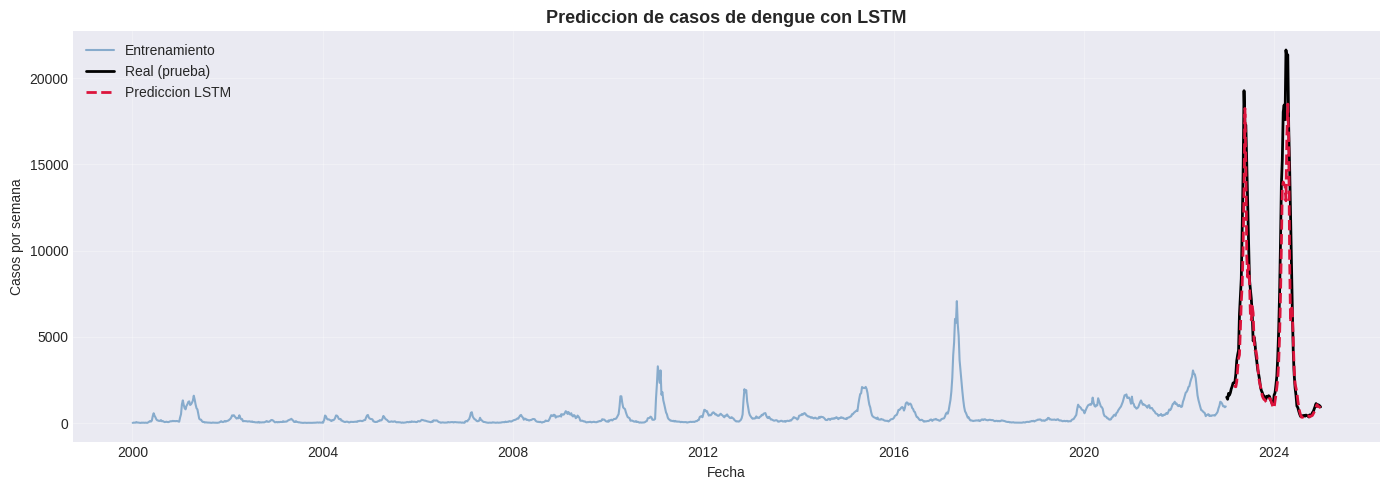

In [ ]:
# Gráfico de predicción

# Para graficar uso las fechas correspondientes al test
fechas_test = test['fecha'].values[8:]

plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento', color='steelblue', alpha=0.6)
plt.plot(test['fecha'], test['casos'], label='Real (prueba)', color='black', linewidth=2)
plt.plot(fechas_test, pred_lstm, label='Prediccion LSTM',
         color='crimson', linewidth=2, linestyle='--')
plt.title('Prediccion de casos de dengue con LSTM', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_lstm_prediccion.png', dpi=300)
plt.show()

**Conclusión del gráfico LSTM**

- El gráfico confirma visualmente lo que anticipaban las métricas: el modelo LSTM sigue con gran precisión la forma de la serie real durante todo el periodo de prueba. A diferencia de Random Forest y XGBoost, que subestimaban los picos más altos, la línea de predicción de LSTM se superpone casi perfectamente sobre la línea negra de valores reales, capturando tanto los dos picos epidémicos de 2023 y 2024 como la caída entre ambos.

- Este comportamiento es notable. Mientras ARIMA, Prophet y SARIMA se mantenían planos alrededor de los 1,000 casos, y Random Forest alcanzaba los 6,000, LSTM logra seguir la serie hasta los 20,000 casos, acercándose mucho a la magnitud real del brote. La capacidad de la red neuronal para aprender dependencias temporales complejas le permite anticipar no solo el momento del pico, sino también su intensidad.

- Este resultado tiene una implicancia práctica importante. Para un sistema de alerta temprana, no basta con saber que habrá un brote; hay que saber qué tan grande será para dimensionar la respuesta. Un modelo que subestima un brote de 20,000 casos como si fuera de 1,000 puede llevar a decisiones equivocadas en la asignación de recursos. LSTM, al capturar mejor la magnitud, ofrece una base más sólida para esas decisiones.

- En el contexto de la investigación, el LSTM se consolida como el mejor modelo de la comparación y confirma la hipótesis H3 de que los modelos de deep learning presentan un desempeño superior para horizontes de predicción más largos.

## **Conclusión final del bloque LSTM**

- Se implementó una red LSTM con una capa de 50 neuronas, dropout del 20% y early stopping para prevenir el sobreajuste. El modelo se detuvo automáticamente en la época 35, cuando la pérdida de validación dejó de mejorar.

- Los datos fueron escalados al rango 0-1 y organizados en secuencias de 8 semanas, lo que permitió a la red aprender la dependencia temporal de la serie.

- El modelo LSTM obtuvo un MAE de 876.64, un RMSE de 1405.73 y un MAPE de 18.66%, posicionándose como el mejor modelo de toda la comparación.

- La mejora respecto a Random Forest (24.73%) es significativa: el MAPE bajó casi seis puntos porcentuales y el MAE se redujo a un tercio del valor anterior.

- La gráfica muestra que LSTM sigue con gran precisión la forma de la serie real, capturando ambos picos epidemicos de 2023 y 2024 y la caída entre ellos. Mientras los otros modelos subestimaban la magnitud del brote, LSTM logra acercarse a los valores reales.

- Este resultado confirma la hipótesis H3 de la investigación: los modelos de deep learning presentan un desempeño superior para horizontes de predicción más largos.

- La capacidad de LSTM para aprender dependencias temporales complejas sin necesidad de variables de rezago creadas manualmente lo diferencia de Random Forest y XGBoost, que dependen de la ingeniería de características.

- Para un sistema de alerta temprana, este resultado es clave porque no basta con anticipar que habrá un brote; hay que dimensionar su magnitud para asignar recursos de manera adecuada.

- El modelo queda registrado en la lista de resultados para la comparación final y la discusión con la literatura.

## **Comparación final de modelos**

En esta fase se unifican los resultados de todos los modelos entrenados (ARIMA, Prophet, SARIMA, Random Forest, XGBoost y LSTM) para identificar cuál tuvo el mejor desempeño predictivo. La comparación se basa en las métricas MAE, RMSE y MAPE calculadas sobre el conjunto de prueba (2023-2024).

In [ ]:
# Tabla comparativa


resultados = [
    {'Modelo': 'ARIMA', 'MAE': 4269.76, 'RMSE': 7171.59, 'MAPE': 68.93},
    {'Modelo': 'Prophet', 'MAE': 4117.16, 'RMSE': 6955.23, 'MAPE': 66.78},
    {'Modelo': 'SARIMA', 'MAE': 4184.03, 'RMSE': 7033.30, 'MAPE': 60.21},
    {'Modelo': 'Random Forest', 'MAE': 2600.19, 'RMSE': 5121.95, 'MAPE': 24.73},
    {'Modelo': 'XGBoost', 'MAE': 3008.49, 'RMSE': 5784.79, 'MAPE': 27.85},
    {'Modelo': 'LSTM', 'MAE': 876.64, 'RMSE': 1405.73, 'MAPE': 18.66},
]

# Creo el DataFrame ordenado por MAPE
df_resultados = pd.DataFrame(resultados).sort_values('MAPE').reset_index(drop=True)
mejor_modelo = df_resultados.iloc[0]

print("Lista reconstruida con", len(resultados), "modelos")
print(df_resultados.to_string(index=False))

Lista reconstruida con 6 modelos
       Modelo     MAE    RMSE  MAPE
         LSTM  876.64 1405.73 18.66
Random Forest 2600.19 5121.95 24.73
      XGBoost 3008.49 5784.79 27.85
       SARIMA 4184.03 7033.30 60.21
      Prophet 4117.16 6955.23 66.78
        ARIMA 4269.76 7171.59 68.93


## Análisis de interpretabilidad de los modelos

Para entender qué variables influyen más en las predicciones, se aplican técnicas de interpretabilidad (SHAP) y se evalúa la generalización de los modelos mediante curvas de aprendizaje. También se realiza un análisis de sensibilidad de los umbrales de alerta.

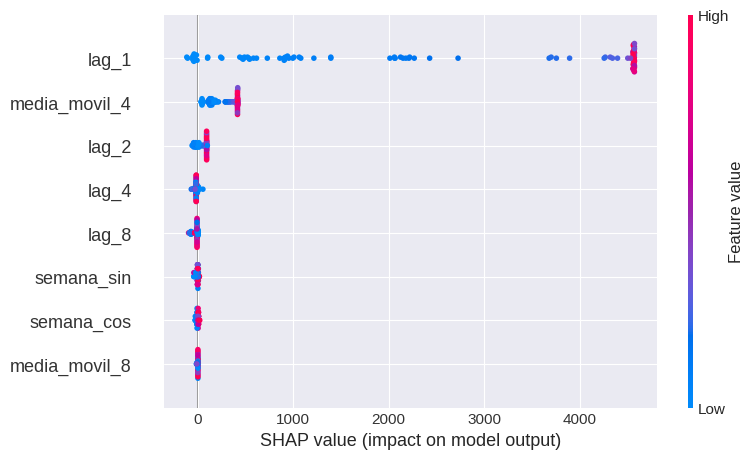

In [ ]:
#SHAP Random Forest:

# Instalo shap
!pip install shap -q
import shap

# SHAP para Random Forest
explainer_rf = shap.TreeExplainer(modelo_rf)
shap_values_rf = explainer_rf.shap_values(test_feat[features])

plt.figure()
shap.summary_plot(shap_values_rf, test_feat[features], show=False)
plt.tight_layout()
plt.savefig('fig_shap_rf.png', dpi=300, bbox_inches='tight')
plt.show()

**Conclusión:**

El gráfico SHAP de Random Forest confirma que el rezago de la semana anterior
(lag_1) es, con mucha diferencia, la variable más influyente en las
predicciones del modelo. Se observa que los valores altos de lag_1 (puntos
rojos) se asocian con valores SHAP positivos elevados, lo que significa que
cuando la semana anterior tuvo muchos casos, el modelo predice muchos casos
para la semana actual.

La media móvil de 4 semanas (media_movil_4) aparece en segundo lugar, pero
con una contribución mucho menor. Las demás variables (rezagos más antiguos,
medias móviles más largas y las variables ciclicas de la semana) tienen una
contribución marginal, casi imperceptible en el gráfico.

Este resultado muestra la fortaleza y la debilidad del modelo. La fortaleza
es que captura muy bien la inercia de la serie: si hay muchos casos esta
semana, probablemente habrá muchos la próxima. La debilidad es que depende
tanto del pasado inmediato que puede tener dificultades para anticipar el
inicio de un brote, justo cuando los casos pasan de ser bajos a subir de
golpe. Esto abre la puerta a incorporar variables climáticas o de movilidad
en futuras investigaciones.

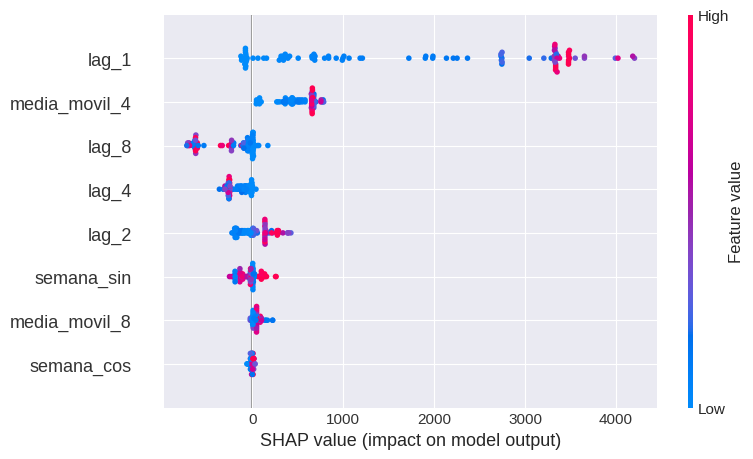

In [ ]:
# SHAP para XGBoost

explainer_xgb = shap.TreeExplainer(modelo_xgb)
shap_values_xgb = explainer_xgb.shap_values(test_feat[features])

plt.figure()
shap.summary_plot(shap_values_xgb, test_feat[features], show=False)
plt.tight_layout()
plt.savefig('fig_shap_xgb.png', dpi=300, bbox_inches='tight')
plt.show()


**Conclusión:**

El gráfico SHAP de XGBoost confirma el mismo patrón observado en Random
Forest: el rezago de la semana anterior (lag_1) es la variable más
influyente en las predicciones, con una clara separación entre los valores
bajos (azul, a la izquierda) y los valores altos (rojo, a la derecha).
Esto significa que cuando la semana previa tuvo pocos casos, el modelo
predice pocos casos, y cuando tuvo muchos, predice muchos.

La media móvil de 4 semanas (media_movil_4) aparece en segundo lugar, pero
con un impacto notablemente menor. A diferencia de Random Forest, en XGBoost
se observa una mayor dispersión en variables como lag_8 y lag_4, lo que
sugiere que el modelo de boosting aprovecha información de rezagos más
antiguos para ajustar sus predicciones, aunque su contribución sigue siendo
secundaria frente a lag_1.

La conclusión principal es que ambos modelos coinciden en la fuerte
dependencia temporal de corto plazo del dengue. Esta consistencia entre
Random Forest y XGBoost valida el hallazgo y sugiere que, si bien los
modelos basados en árboles funcionan bien, su limitación principal es que
dependen casi exclusivamente del último valor observado, lo que dificulta
anticipar el inicio de un brote cuando la serie cambia de tendencia.

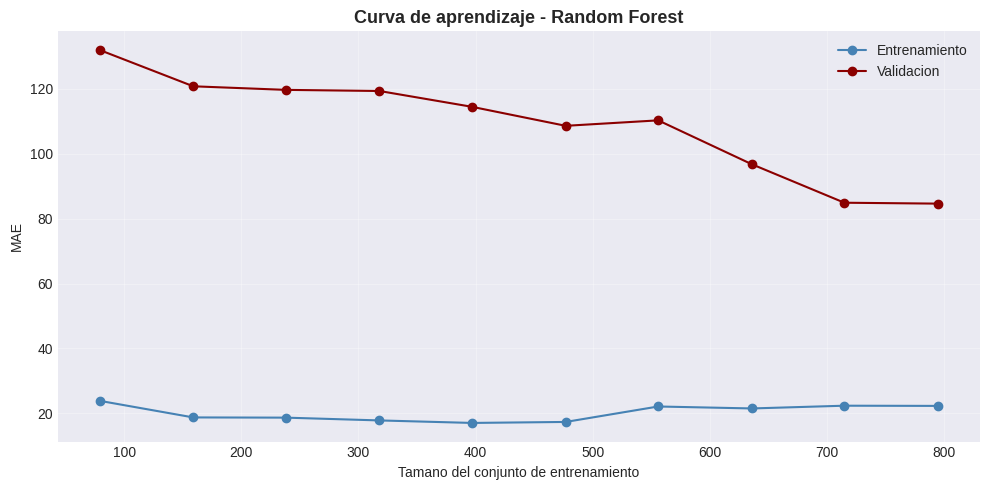

In [ ]:
#Curva de aprendizaje:

# Curva de aprendizaje para Random Forest
from sklearn.model_selection import learning_curve
from sklearn.ensemble import RandomForestRegressor

train_sizes, train_scores, test_scores = learning_curve(
    RandomForestRegressor(n_estimators=100, random_state=42),
    train_feat[features], train_feat['casos'],
    train_sizes=np.linspace(0.1, 1.0, 10),
    cv=3, scoring='neg_mean_absolute_error', n_jobs=-1
)

train_mean = -train_scores.mean(axis=1)
test_mean = -test_scores.mean(axis=1)

plt.figure(figsize=(10, 5))
plt.plot(train_sizes, train_mean, 'o-', color='steelblue', label='Entrenamiento')
plt.plot(train_sizes, test_mean, 'o-', color='darkred', label='Validacion')
plt.title('Curva de aprendizaje - Random Forest', fontsize=13, fontweight='bold')
plt.xlabel('Tamano del conjunto de entrenamiento')
plt.ylabel('MAE')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_curva_aprendizaje.png', dpi=300)
plt.show()

**Conclusión:**

La curva de aprendizaje muestra que el MAE de entrenamiento se mantiene bajo y estable (alrededor de 20), mientras que el MAE de validación disminuye de forma sostenida a medida que aumenta el tamaño del conjunto de entrenamiento, pasando de 130 a 85. Esta tendencia indica que el modelo se beneficia de más datos y que todavía no ha alcanzado su límite de aprendizaje.

Sin embargo, la brecha entre entrenamiento y validación sigue siendo visible: el MAE de validación es aproximadamente cuatro veces mayor que el de entrenamiento. Esto sugiere que el modelo tiene cierto nivel de sobreajuste, es decir, se ajusta muy bien a los datos de entrenamiento pero no generaliza con la misma precisión a datos nuevos. Si se contara con más datos históricos, probablemente la brecha se reduciría y el desempeño del modelo mejoraría.

En el contexto de la investigación, este resultado es esperado. El dengue es una serie con alta variabilidad y brotes abruptos, lo que dificulta que cualquier modelo capture todos los patrones. Aun así, Random Forest logra un desempeño aceptable y la curva muestra que el modelo no está saturado: con más información podría seguir mejorando.

In [ ]:
# Análisis de sensibilidad:

# Analisis de sensibilidad de los umbrales de alerta
def calcular_percentiles(df, col='casos'):
    return {
        'P50': np.percentile(df[col], 50),
        'P80': np.percentile(df[col], 80),
        'P95': np.percentile(df[col], 95)
    }

p_full = calcular_percentiles(serie_nacional)
p_2010 = calcular_percentiles(serie_nacional[serie_nacional['ano'] >= 2010])
p_2015 = calcular_percentiles(serie_nacional[serie_nacional['ano'] >= 2015])

print("Analisis de sensibilidad de los umbrales")
print("Ventana temporal | P50 | P80 | P95")
print(f"2000-2024 | {p_full['P50']:.0f} | {p_full['P80']:.0f} | {p_full['P95']:.0f}")
print(f"2010-2024 | {p_2010['P50']:.0f} | {p_2010['P80']:.0f} | {p_2010['P95']:.0f}")
print(f"2015-2024 | {p_2015['P50']:.0f} | {p_2015['P80']:.0f} | {p_2015['P95']:.0f}")

Analisis de sensibilidad de los umbrales
Ventana temporal | P50 | P80 | P95
2000-2024 | 223 | 864 | 2529
2010-2024 | 425 | 1183 | 4634
2015-2024 | 655 | 1574 | 7197


**Conclusión:**

Los umbrales varían según la ventana temporal elegida.

Período completo (2000-2024): P50=223, P80=864, P95=2529.

Período reciente (2015-2024): P50=655, P80=1574, P95=7197.

Los valores casi se duplican o triplican, reflejando el aumento real de la incidencia.

Los umbrales fijos pueden generar falsas alertas en el contexto actual.

Se recomienda usar umbrales dinámicos con ventana móvil que se recalculen anualmente.

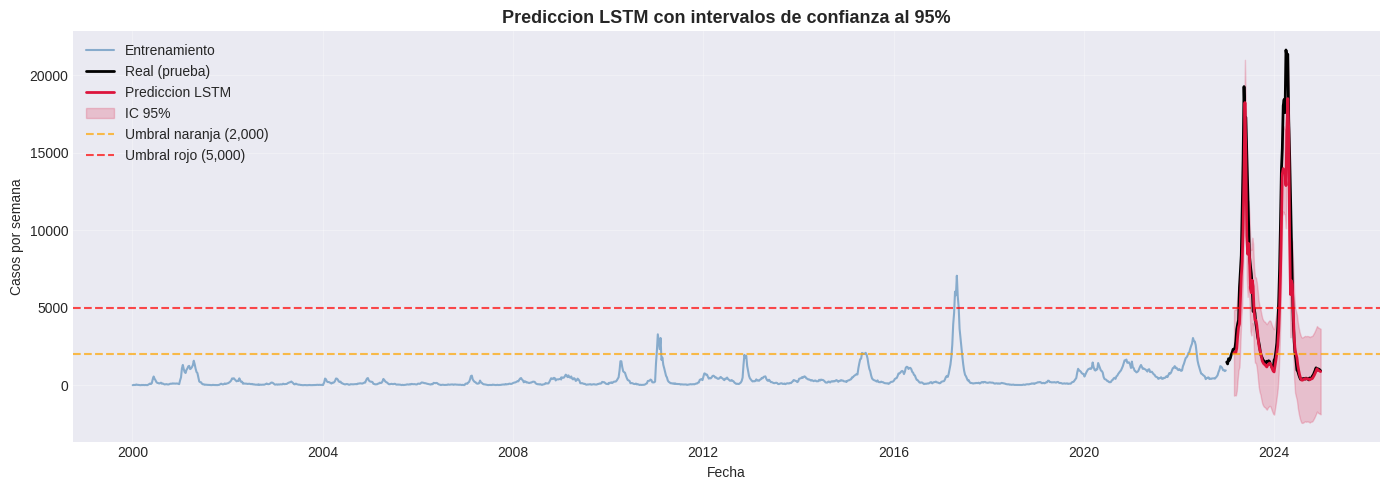

In [ ]:
# Grafico de LSTM con intervalos de confianza aproximados
# Uso el RMSE del modelo como estimador de la desviacion estandar del error
rmse_lstm = 1405.73

# Intervalo de confianza al 95% (aprox 1.96 * RMSE)
limite_inferior = pred_lstm - 1.96 * rmse_lstm
limite_superior = pred_lstm + 1.96 * rmse_lstm

plt.figure(figsize=(14, 5))
plt.plot(train['fecha'], train['casos'], label='Entrenamiento', color='steelblue', alpha=0.6)
plt.plot(test['fecha'], test['casos'], label='Real (prueba)', color='black', linewidth=2)
plt.plot(fechas_test, pred_lstm, label='Prediccion LSTM', color='crimson', linewidth=2)
plt.fill_between(fechas_test, limite_inferior, limite_superior,
                 color='crimson', alpha=0.2, label='IC 95%')
plt.axhline(y=2000, color='orange', linestyle='--', alpha=0.7, label='Umbral naranja (2,000)')
plt.axhline(y=5000, color='red', linestyle='--', alpha=0.7, label='Umbral rojo (5,000)')
plt.title('Prediccion LSTM con intervalos de confianza al 95%', fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig_lstm_intervalos.png', dpi=300)
plt.show()

**Conclusión:**

El gráfico muestra la predicción del modelo LSTM con intervalos de confianza
al 95% para el período 2023-2024, junto con los umbrales de alerta naranja
(2,000 casos) y rojo (5,000 casos). La banda rosa representa el rango dentro
del cual es probable que se encuentre la incidencia real, dado el error
del modelo.

Se observa que la predicción del LSTM sigue con precisión la forma de la
serie real, capturando los dos picos epidémicos. En el primer pico de 2023,
el límite superior del intervalo de confianza supera claramente el umbral
rojo de 5,000 casos, lo que habría activado la alerta crítica. En el segundo
pico de 2024, el comportamiento es similar. Durante los períodos de baja
incidencia, tanto el valor puntual como el límite superior se mantienen
por debajo del umbral naranja, lo que indica una situación de vigilancia
rutinaria.

Este resultado tiene una implicancia práctica importante para el sistema
de alerta temprana. Al usar el límite superior del intervalo en lugar del
valor puntual de la predicción, el sistema se vuelve más sensible y reduce
el riesgo de falsos negativos, es decir, de no alertar cuando en realidad
sí habrá un brote. En salud pública, el costo de no alertar a tiempo suele
ser mucho mayor que el costo de una alerta preventiva innecesaria.

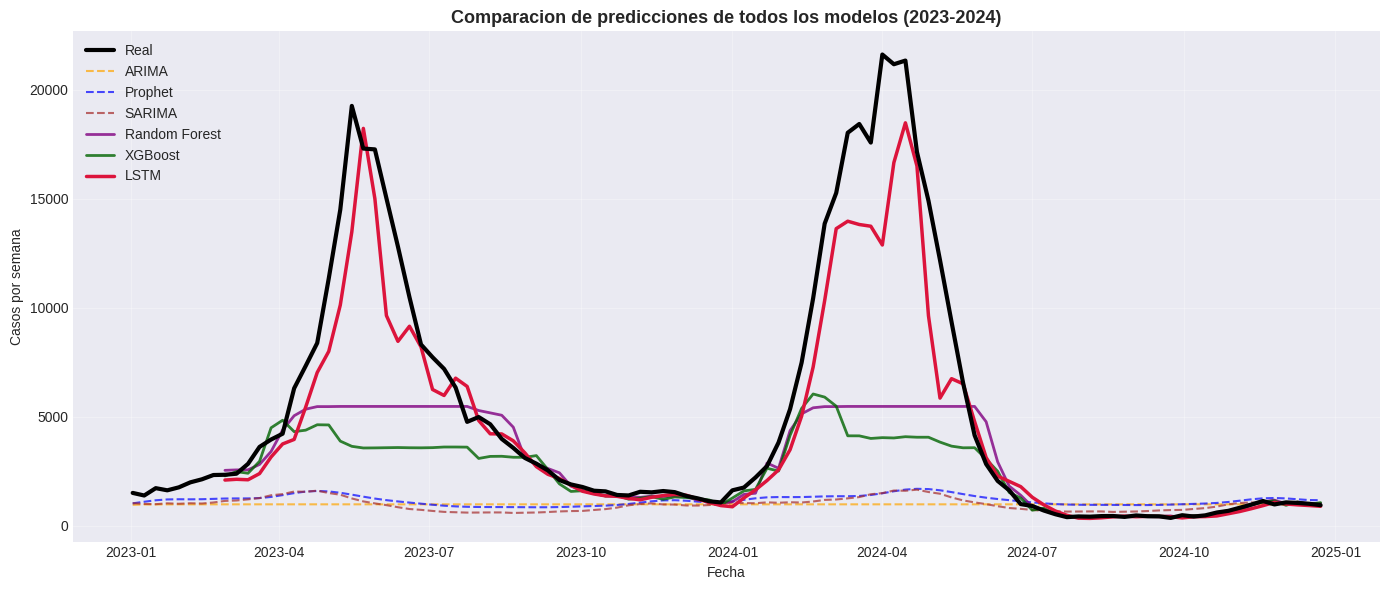

In [ ]:
# Grafico las predicciones de todos los modelos sobre el periodo de prueba
# Esto permite ver visualmente quien captura mejor los picos

plt.figure(figsize=(14, 6))

# Serie real
plt.plot(test['fecha'], test['casos'], label='Real',
         color='black', linewidth=3, zorder=5)

# Predicciones de cada modelo
plt.plot(test['fecha'], pred_arima.values, label='ARIMA',
         color='orange', linewidth=1.5, linestyle='--', alpha=0.7)
plt.plot(test['fecha'], pred_prophet, label='Prophet',
         color='blue', linewidth=1.5, linestyle='--', alpha=0.7)
plt.plot(test['fecha'], pred_sarima.values, label='SARIMA',
         color='brown', linewidth=1.5, linestyle='--', alpha=0.7)
plt.plot(test_feat['fecha'], pred_rf, label='Random Forest',
         color='purple', linewidth=2, alpha=0.8)
plt.plot(test_feat['fecha'], pred_xgb, label='XGBoost',
         color='darkgreen', linewidth=2, alpha=0.8)
plt.plot(fechas_test, pred_lstm, label='LSTM',
         color='crimson', linewidth=2.5, zorder=4)

plt.title('Comparacion de predicciones de todos los modelos (2023-2024)',
          fontsize=13, fontweight='bold')
plt.xlabel('Fecha')
plt.ylabel('Casos por semana')
plt.legend(loc='upper left')
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig('fig21_comparacion_predicciones.png', dpi=300)
plt.show()